## 1. Carregamento e inspeção inicial

Esta célula importa as bibliotecas utilizadas e carrega as bases climática, de perdas de água e de renda. O objetivo é preparar os dados para a análise e visualizar os primeiros registros de cada fonte.

In [1]:
import pandas as pd
import geopandas as gpd
import requests
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import skew, kurtosis
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score, pairwise_distances
from mpl_toolkits.mplot3d import Axes3D
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import os, warnings
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score
from sklearn.neighbors import BallTree, NearestNeighbors
from sklearn.model_selection import KFold
warnings.filterwarnings('ignore', category=FutureWarning)

# Base climática: produto MERGE/INPE via cruzamento espacial (satélite)
# colunas: 'id' (codigo IBGE 7 dígitos), 'name' (nome do município), 'dias_consecutivos' (CDD max em 2022)
df_clima = pd.read_csv('dias_consecutivos_seca.csv')

df_agua = pd.read_csv(
    'perdaDeAgua.csv',
    sep=';',
    encoding='latin1',
    skiprows=1,
    header=None,
    names=[
        'id_municipio',
        'municipio',
        'estado',
        'ano_referencia',
        'id_prestador',
        'prestador',
        'sigla_prestador',
        'abrangencia',
        'tipo_servico',
        'natureza_juridica',
        'indice_perdas_distribuicao'
    ],
    usecols=range(11),
    decimal=','
)
df_renda = pd.read_csv(
    'rendaPerCapitaSP.csv',
    skiprows=6,
    header=None,
    names=['id_municipio', 'municipio', 'grupo_idade', 'renda_per_capita'],
    encoding='utf-8-sig'
)

# inspecionando as colunas e os primeiros registros
display("--- Dados Climáticos (CDD — satélite MERGE/INPE) ---", df_clima.head())
display("--- Dados de Perda de Água (SNIS) ---", df_agua.head())
display("--- Dados de Renda (IBGE) ---", df_renda.head())


'--- Dados Climáticos (CDD — satélite MERGE/INPE) ---'

,id,name,dias_consecutivos
0,3500105,Adamantina,50
1,3500204,Adolfo,27
2,3500303,Aguaí,47
3,3500402,Águas da Prata,47
4,3500550,Águas de Santa Bárbara,47


'--- Dados de Perda de Água (SNIS) ---'

,id_municipio,municipio,estado,ano_referencia,id_prestador,prestador,sigla_prestador,abrangencia,tipo_servico,natureza_juridica,indice_perdas_distribuicao
0,350010,Adamantina,SP,2022,35503000,Companhia de Saneamento Básico do Estado de Sã...,SABESP,Regional,Água e Esgoto,Sociedade de economia mista com administração ...,23.85
1,350020,Adolfo,SP,2022,35503000,Companhia de Saneamento Básico do Estado de Sã...,SABESP,Regional,Água e Esgoto,Sociedade de economia mista com administração ...,9.72
2,350030,Aguaí,SP,2022,35503000,Companhia de Saneamento Básico do Estado de Sã...,SABESP,Regional,Água e Esgoto,Sociedade de economia mista com administração ...,66.99
3,350040,Águas da Prata,SP,2022,35503000,Companhia de Saneamento Básico do Estado de Sã...,SABESP,Regional,Água e Esgoto,Sociedade de economia mista com administração ...,35.38
4,350050,Águas de Lindóia,SP,2022,35005011,Saneamento Ambiental de Águas de Lindóia,SAAE,Local,Água e Esgoto,Autarquia,40.03


'--- Dados de Renda (IBGE) ---'

,id_municipio,municipio,grupo_idade,renda_per_capita
0,3500105,Adamantina (SP),Total,1868.26
1,3500204,Adolfo (SP),Total,1514.80
2,3500303,Aguaí (SP),Total,1321.67
3,3500402,Águas da Prata (SP),Total,1684.99
4,3500501,Águas de Lindóia (SP),Total,1742.52


O uso de latin1 e utf-8-sig garante a leitura correta de acentuação e caracteres especiais em português, enquanto os parâmetros de mapeamento de colunas evitam erros estruturais no carregamento das tabelas tabulares.

## 3. Aplicação da otimização e inspeção de nulos


In [2]:
# o df_clima usa 'id' como chave (codigo IBGE de 7 digitos, oriundo do GeoJSON do IBGE usado no cruzamento espacial).
# df_agua e df_renda usam 'id_municipio'. O merge sera feito pelos 6 primeiros dígitos (padrão IBGE sem dígito verificador).

# verificacao inicial de nulos e tipos (MCAR, MAR, MNAR)
print("--- Nulos no Clima --- \n", df_clima.isna().sum())
print("--- Nulos na Água --- \n", df_agua.isna().sum())
print("--- Nulos na Renda --- \n", df_renda.isna().sum())


--- Nulos no Clima --- 
 id                   0
name                 0
dias_consecutivos    0
dtype: int64
--- Nulos na Água --- 
 id_municipio                  0
municipio                     0
estado                        0
ano_referencia                0
id_prestador                  0
prestador                     0
sigla_prestador               0
abrangencia                   0
tipo_servico                  0
natureza_juridica             0
indice_perdas_distribuicao    4
dtype: int64
--- Nulos na Renda --- 
 id_municipio         1
municipio           10
grupo_idade         17
renda_per_capita    17
dtype: int64


### Interpretação dos resultados

Na base de perdas de água, foram identificados 4 valores ausentes na coluna `indice_perdas_distribuicao` (um deles é a linha de total da amostra, `TOTAL da AMOSTRA`). Como essa variável é essencial para as análises de eficiência do saneamento, esses registros serão removidos na etapa de limpeza. Além dos ausentes, há **10 registros com índice exatamente igual a 0,00%**, que não aparecem como nulos mas também não são dados válidos; eles são tratados na seção 4.1.

Na base de renda, há 17 valores ausentes em `renda_per_capita`, 10 em `municipio` e 1 em `id_municipio`. Os registros sem renda ou sem identificador municipal serão removidos.

A base climática não apresenta valores ausentes: as 599 linhas correspondem aos municípios para os quais o cruzamento espacial dos pixels do satélite MERGE/INPE com a malha municipal do IBGE gerou pelo menos um pixel de precipitação. Os 46 municípios restantes serão tratados na etapa de imputação espacial (seção 25).

## 4. Remoção de registros incompletos

Esta célula elimina os registros sem valores essenciais nas bases de água e renda e ajusta o tipo do identificador municipal. O objetivo é evitar falhas nas análises e nos cruzamentos posteriores.

In [3]:
# Removendo os 4 nulos do indice de perdas
df_agua.dropna(subset=['indice_perdas_distribuicao'], inplace=True)

# Removendo os 17 nulos da renda e 1 nulo do id_municipio
df_renda.dropna(subset=['renda_per_capita', 'id_municipio'], inplace=True)

# O id_municipio no df_renda provavelmente virou float por causa do nulo, vamos garantir que seja int64
df_renda['id_municipio'] = df_renda['id_municipio'].astype('int64')

print(f"Linhas restantes em Água: {len(df_agua)}")
print(f"Linhas restantes em Renda: {len(df_renda)}")

Linhas restantes em Água: 643
Linhas restantes em Renda: 645


In [4]:
# Índice de perdas exatamente igual a 0,00% = dado NÃO INFORMADO (não é eficiência perfeita):
# toda rede real tem vazamento, erro de medição ou consumo não faturado.
z0 = df_agua['indice_perdas_distribuicao'].eq(0)
menor_positivo = df_agua.loc[~z0, 'indice_perdas_distribuicao'].min()
pref0 = df_agua['natureza_juridica'].eq('Administração pública direta')

df_perdas_zero = (df_agua.loc[z0, ['id_municipio', 'municipio', 'prestador', 'natureza_juridica', 'abrangencia', 'tipo_servico']]
                  .reset_index(drop=True))
df_perdas_zero['id_municipio'] = df_perdas_zero['id_municipio'].astype('int64')

print(f'Registros com índice de perdas = 0,00%: {z0.sum()}  (o menor valor positivo da base é {menor_positivo:.2f}%)')
print(f'  Prefeituras com administração direta: {(z0 & pref0).sum()} de {pref0.sum()} ({100 * (z0 & pref0).sum() / pref0.sum():.1f}%)')
print(f'  Demais naturezas jurídicas:           {(z0 & ~pref0).sum()} de {(~pref0).sum()} ({100 * (z0 & ~pref0).sum() / (~pref0).sum():.1f}%)')
display(df_perdas_zero)

# Os 10 saem da base de modelagem; ficam guardados em df_perdas_zero (mapas e conferência no SNIS)
df_agua = df_agua.loc[~z0].copy()
print(f'\nLinhas restantes em Água após excluir os 10 registros com 0,00%: {len(df_agua)}')


Registros com índice de perdas = 0,00%: 10  (o menor valor positivo da base é 0.02%)
  Prefeituras com administração direta: 9 de 150 (6.0%)
  Demais naturezas jurídicas:           1 de 493 (0.2%)


,id_municipio,municipio,prestador,natureza_juridica,abrangencia,tipo_servico
0,351360,Cunha,Prefeitura Municipal de Cunha,Administração pública direta,Local,Água e Esgoto
1,351730,Guaimbê,Prefeitura Municipal de Guaimbê,Administração pública direta,Local,Água e Esgoto
2,352060,Indiana,Prefeitura Municipal de Indiana,Administração pública direta,Local,Água e Esgoto
3,352650,Lavínia,Prefeitura Municipal de Lavínia,Administração pública direta,Local,Água e Esgoto
4,353325,Novais,Prefeitura Municipal de Novais,Administração pública direta,Local,Água e Esgoto
5,353640,Paulicéia,Prefeitura Municipal de Paulicéia,Administração pública direta,Local,Água e Esgoto
6,354370,Rincão,Prefeitura Municipal de Rincão,Administração pública direta,Local,Água e Esgoto
7,354660,Santa Fé do Sul,Serviço Autônomo de Água e Esgoto,Autarquia,Local,Água e Esgoto
8,355320,Taiúva,Prefeitura Municipal de Taiuva,Administração pública direta,Local,Água e Esgoto
9,355365,Taquaral,Prefeitura Municipal de Taquaral,Administração pública direta,Local,Água e Esgoto



Linhas restantes em Água após excluir os 10 registros com 0,00%: 633


### Interpretação: perdas iguais a 0,00%

Dez registros têm índice de perdas **exatamente igual a 0,00%**, enquanto o menor valor positivo da base é 0,02%. Nove são prefeituras com administração direta (6,0% das 150 prefeituras da base) e uma é uma autarquia (Santa Fé do Sul); entre as demais 493 naturezas jurídicas, é apenas 0,2%. Perda nula em uma rede real é fisicamente implausível (há sempre vazamento, erro de medição ou consumo não faturado), e a concentração em prefeituras que operam diretamente os serviços sugere que o campo foi deixado em branco ou preenchido com zero no envio ao SNIS.

Por isso o valor é tratado como **dado ausente**: os 10 municípios saem da base de modelagem (que passa de 643 para **633 linhas** de perdas) e ficam guardados em `df_perdas_zero`, para aparecerem hachurados nos mapas e para serem conferidos no SNIS. Manter o zero faria esses municípios parecerem perfeitamente eficientes e os colocaria em clusters aos quais provavelmente não pertencem. A seção 28.6 mostra a classificação provisória deles, só como indicação.

**Pendência para o grupo:** conferir esses 10 valores diretamente no SNIS (série histórica, indicador IN049) e, se houver valor válido, incluí-los na base.

### Interpretação dos resultados

Após a remoção dos valores ausentes, a base de perdas de água passou a conter **643 linhas**: os 4 registros sem valor em `indice_perdas_distribuicao` foram excluídos, pois não poderiam contribuir para as análises de eficiência do saneamento.

A base de renda passou a conter **645 linhas**. Foram removidos os registros sem `renda_per_capita` e o registro sem `id_municipio`, já que essas informações são necessárias para comparar os municípios e realizar os cruzamentos entre as bases.

Por fim, `id_municipio` foi convertido para `int64` após a remoção dos valores ausentes. Essa padronização evita problemas de tipo durante os merges e garante que os identificadores municipais sejam tratados como códigos inteiros nas etapas seguintes.

## 5. Identificação de outliers

Esta célula calcula os limites do intervalo interquartil e identifica valores extremos nas variáveis de renda, perdas de água e dias secos. O objetivo é avaliar a presença e a proporção de outliers.

In [5]:
def verificar_outliers_iqr(df, coluna):
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1
    
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    
    outliers = df[(df[coluna] < limite_inferior) | (df[coluna] > limite_superior)]
    percentual = (len(outliers) / len(df)) * 100
    
    print(f"-> {coluna}: {len(outliers)} outliers identificados ({percentual:.2f}% da base)")
    
    display(outliers.sort_values(by=coluna, ascending=False).head())

print("=== Verificação Estatística de Outliers (Método IQR) ===")
verificar_outliers_iqr(df_renda, 'renda_per_capita')
verificar_outliers_iqr(df_agua, 'indice_perdas_distribuicao')
verificar_outliers_iqr(df_clima, 'dias_consecutivos')


=== Verificação Estatística de Outliers (Método IQR) ===
-> renda_per_capita: 24 outliers identificados (3.72% da base)


,id_municipio,municipio,grupo_idade,renda_per_capita
545,3548807,São Caetano do Sul (SP),Total,3884.58
528,3547304,Santana de Parnaíba (SP),Total,3465.07
636,3556701,Vinhedo (SP),Total,3247.77
542,3548500,Santos (SP),Total,3237.52
629,3556206,Valinhos (SP),Total,3127.28


-> indice_perdas_distribuicao: 17 outliers identificados (2.69% da base)


,id_municipio,municipio,estado,ano_referencia,id_prestador,prestador,sigla_prestador,abrangencia,tipo_servico,natureza_juridica,indice_perdas_distribuicao
364,353230,Natividade da Serra,SP,2022,35323011,Prefeitura Municipal de Natividade da Serra,PMNS,Local,Água e Esgoto,Administração pública direta,89.63
334,352950,Mendonça,SP,2022,35295011,Prefeitura Municipal de Mendonça,PMM,Local,Água e Esgoto,Administração pública direta,80.08
457,354075,Potim,SP,2022,35407512,Águas de Potim SPE LTDA,AP,Local,Água e Esgoto,Empresa privada,76.58
241,352090,Ipaussu,SP,2022,35209011,Prefeitura Municipal de Ipaussu,PMI,Local,Água e Esgoto,Administração pública direta,76.35
119,351040,Capivari,SP,2022,35104011,Serviço Autônomo de Água e Esgoto,SAAE,Local,Água e Esgoto,Autarquia,75.39


-> dias_consecutivos: 5 outliers identificados (0.83% da base)


,id,name,dias_consecutivos
31,3503000,Aramina,85
61,3505906,Batatais,84
468,3544905,Sales Oliveira,84
261,3525102,Jardinópolis,83
357,3534302,Orlândia,83


### Interpretação dos resultados

A análise pelo método do intervalo interquartil (IQR) identificou **24 outliers na renda per capita** (~3,72% da base) e **17 outliers em perdas de distribuição** (~2,69% da base, já sem os registros com 0,00%). Já a variável **dias_consecutivos** apresentou **5 outliers** (~0,83% da base), com valores acima de **75,5 dias** (83 a 85 dias). Esses valores são plausíveis dentro do contexto climático e econômico regional e não configuram erros de dado.

## 6. Visualização dos outliers

Esta célula cria boxplots comparativos para renda, perdas de água e dias consecutivos secos. O objetivo é visualizar a dispersão e os valores extremos encontrados na etapa anterior.

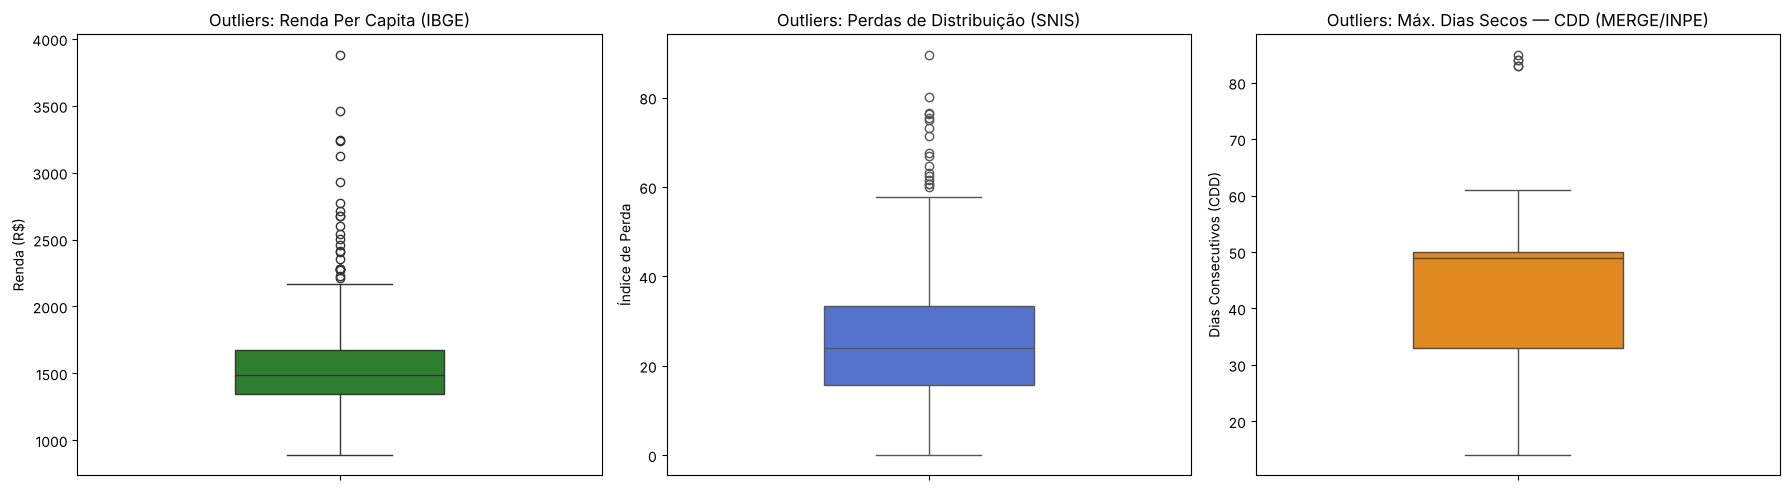

In [6]:
# cria uma figura com 3 graficos lado a lado
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# boxplot da Renda Per Capita
sns.boxplot(y=df_renda['renda_per_capita'], ax=axes[0], color='forestgreen', width=0.4)
axes[0].set_title('Outliers: Renda Per Capita (IBGE)')
axes[0].set_ylabel('Renda (R$)')

# boxplot das Perdas de Distribuição
sns.boxplot(y=df_agua['indice_perdas_distribuicao'], ax=axes[1], color='royalblue', width=0.4)
axes[1].set_title('Outliers: Perdas de Distribuição (SNIS)')
axes[1].set_ylabel('Índice de Perda')

# boxplot do Clima (CDD) — satélite MERGE/INPE
sns.boxplot(y=df_clima['dias_consecutivos'], ax=axes[2], color='darkorange', width=0.4)
axes[2].set_title('Outliers: Máx. Dias Secos — CDD (MERGE/INPE)')
axes[2].set_ylabel('Dias Consecutivos (CDD)')

# ajusta o espacamento para nao sobrepor os titulos
plt.tight_layout()
plt.show()


### Interpretação dos boxplots

Os boxplots confirmam a presença de valores extremos nas variáveis de renda e perdas de água.

- **Renda per capita:** a metade central dos municípios está entre R$ 1.349 e R$ 1.677 (mediana R$ 1.488). O limite superior do boxplot é R$ 2.170,64 e há 24 municípios acima dele, chegando a R$ 3.884,58 (São Caetano do Sul). Isso indica uma distribuição assimétrica à direita, com municípios de renda excepcionalmente alta.

- **Perdas de distribuição:** a metade central está entre 15,8% e 33,4% (mediana 24,1%). O limite superior é 59,8%, e os 17 outliers chegam a 89,6% (Natividade da Serra).

- **Dias consecutivos secos (CDD, satélite MERGE/INPE):** a metade central está entre 33 e 50 dias (mediana 49); os 5 outliers estão acima de 75,5 dias (83 a 85 dias).

## 7. Tratamento de valores extremos

Esta célula guarda uma cópia dos valores brutos (`df_renda_bruto`, `df_agua_bruto`) e define uma função de capping pelo IQR para limitar valores extremos de renda e perdas. O objetivo é reduzir a influência de observações atípicas sem eliminar municípios desnecessariamente. O CDD não é alterado: seus valores (14 a 85 dias) são todos plausíveis.

In [7]:
# cópias ANTES do capping: o capping alterna os valores extremos, e os rankings (seção 13) usam os valores brutos
df_renda_bruto = df_renda.copy()
df_agua_bruto = df_agua.copy()

# TRATAMENTO DE RENDA E PERDAS (Winsorização / Capping)
# tosa o valor extremo no limite do bigode do boxplot
def aplicar_capping_iqr(df, coluna):
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    
    # substitui os valores acima do limite pelo proprio valor do limite
    df[coluna] = np.where(df[coluna] > limite_superior, limite_superior, df[coluna])
    return df

aplicar_capping_iqr(df_renda, 'renda_per_capita')
aplicar_capping_iqr(df_agua, 'indice_perdas_distribuicao')
print("Capping aplicado em renda e perdas.")


Capping aplicado em renda e perdas.


### Interpretação do tratamento de valores extremos

Para renda e perdas de água, a função de capping limita valores acima do limite superior do IQR sem excluir os municípios: 24 registros de renda passam a valer R$ 2.170,64 e 17 de perdas passam a valer 59,80%. Todos os registros disponíveis são preservados (645 na base de renda e 633 na de perdas de água). A cópia dos valores brutos é usada na seção 13 para os rankings, porque, depois do capping, os maiores valores ficariam todos iguais ao teto.

## 8. Estatísticas descritivas e histogramas

Esta célula calcula estatísticas resumidas e constrói histogramas das principais variáveis. O objetivo é compreender a distribuição dos dados antes das análises multivariadas.

'Estatísticas - Renda (IBGE):'

count     645.00
mean     1525.15
std       264.02
min       888.50
25%      1348.69
50%      1487.79
75%      1677.47
max      2170.64
Name: renda_per_capita, dtype: float64

'Estatísticas - Perdas (SNIS):'

count    633.00
mean      25.60
std       13.45
min        0.02
25%       15.77
50%       24.06
75%       33.38
max       59.80
Name: indice_perdas_distribuicao, dtype: float64

'Estatísticas - Clima/CDD (MERGE/INPE):'

count    599.00
mean      42.99
std       12.80
min       14.00
25%       33.00
50%       49.00
75%       50.00
max       85.00
Name: dias_consecutivos, dtype: float64

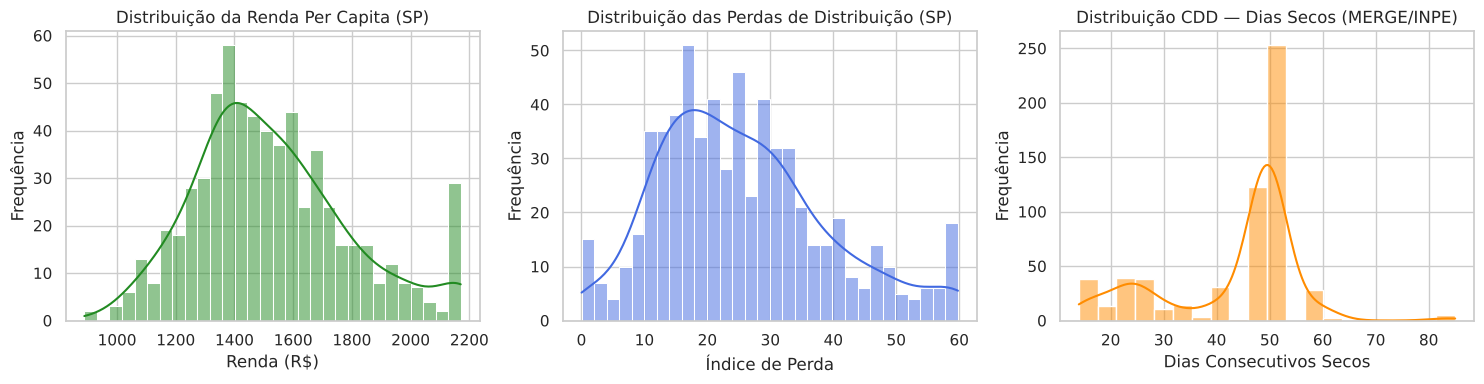

In [8]:
sns.set_theme(style="whitegrid")

# estatisticas descritivas
display("Estatísticas - Renda (IBGE):", df_renda['renda_per_capita'].describe().round(2))
display("Estatísticas - Perdas (SNIS):", df_agua['indice_perdas_distribuicao'].describe().round(2))
display("Estatísticas - Clima/CDD (MERGE/INPE):", df_clima['dias_consecutivos'].describe().round(2))

# histogramas (Grid 1x3)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# histograma: Renda
sns.histplot(df_renda['renda_per_capita'], bins=30, kde=True, ax=axes[0], color='forestgreen')
axes[0].set_title('Distribuição da Renda Per Capita (SP)')
axes[0].set_xlabel('Renda (R$)')
axes[0].set_ylabel('Frequência')

# histograma: Perdas
sns.histplot(df_agua['indice_perdas_distribuicao'], bins=30, kde=True, ax=axes[1], color='royalblue')
axes[1].set_title('Distribuição das Perdas de Distribuição (SP)')
axes[1].set_xlabel('Índice de Perda')
axes[1].set_ylabel('Frequência')

# histograma: Clima 
sns.histplot(df_clima['dias_consecutivos'], bins=20, kde=True, ax=axes[2], color='darkorange')
axes[2].set_title('Distribuição CDD — Dias Secos (MERGE/INPE)')
axes[2].set_xlabel('Dias Consecutivos Secos')
axes[2].set_ylabel('Frequência')

plt.tight_layout()
plt.show()


### Interpretação das distribuições

Os histogramas (após o capping) mostram que as três variáveis têm comportamentos diferentes:

- **Renda per capita:** concentra-se entre R$ 1.349 e R$ 1.677 (quartis), com média de R$ 1.525, mediana de R$ 1.488 e desvio padrão de R$ 264. A cauda à direita termina no teto do capping (R$ 2.171), que reúne 24 municípios.

- **Perdas de água:** concentra-se entre 16% e 33% (quartis), com média de 25,6%, mediana de 24,1% e desvio padrão de 13,5 pontos percentuais. A cauda à direita termina no teto de 59,8%.

- **Dias consecutivos secos (CDD, MERGE/INPE):** a distribuição é **bimodal**: um grupo grande em torno de 48 a 50 dias (mediana 49, terceiro quartil 50) e um segundo grupo, menor, em torno de 15 a 30 dias. A média é ~43 dias e o desvio padrão ~13 dias. O grupo de menor CDD corresponde ao sul e ao litoral do estado (seção 22).

## 9. Assimetria e curtose

Esta célula calcula a assimetria e a curtose das variáveis numéricas. O objetivo é avaliar o formato das distribuições e identificar possíveis caudas longas ou concentração de valores extremos.

In [9]:
def analise_forma(df, coluna, nome_dataset):
    assimetria = skew(df[coluna].dropna())
    curt = kurtosis(df[coluna].dropna())
    
    print(f"--- {nome_dataset} ({coluna}) ---")
    print(f"Assimetria (Skewness): {assimetria:.2f} " 
          f"-> {'> 0 (Cauda à direita, muitos valores baixos)' if assimetria > 0 else '< 0 (Cauda à esquerda)'}")
    print(f"Curtose (Kurtosis): {curt:.2f} "
          f"-> {'> 3 (Muitos outliers pesados)' if curt > 3 else '< 3 (Poucos outliers extremos)'}\n")

analise_forma(df_renda, 'renda_per_capita', 'IBGE')
analise_forma(df_agua, 'indice_perdas_distribuicao', 'SNIS')
analise_forma(df_clima, 'dias_consecutivos', 'MERGE/INPE')


--- IBGE (renda_per_capita) ---
Assimetria (Skewness): 0.57 -> > 0 (Cauda à direita, muitos valores baixos)
Curtose (Kurtosis): 0.06 -> < 3 (Poucos outliers extremos)

--- SNIS (indice_perdas_distribuicao) ---
Assimetria (Skewness): 0.62 -> > 0 (Cauda à direita, muitos valores baixos)
Curtose (Kurtosis): -0.00 -> < 3 (Poucos outliers extremos)

--- MERGE/INPE (dias_consecutivos) ---
Assimetria (Skewness): -0.70 -> < 0 (Cauda à esquerda)
Curtose (Kurtosis): 0.18 -> < 3 (Poucos outliers extremos)



### Interpretação da assimetria e da curtose

As medidas abaixo foram calculadas **depois do capping**; entre parênteses, o valor antes do tratamento (seção 7).

- **Renda per capita:** assimetria de **0,57** (antes: 2,14) e curtose de **0,06** (antes: 8,86). O capping removeu praticamente toda a cauda pesada: poucos municípios de renda muito elevada puxavam a distribuição para a direita.

- **Perdas de água:** assimetria de **0,62** (antes: 0,97) e curtose de ~0,00 (antes: 1,42), indicando uma cauda à direita moderada.

- **Dias consecutivos secos (CDD, MERGE/INPE):** assimetria **negativa** (−0,70): a maioria dos municípios concentra-se em valores altos de CDD (em torno de 50 dias), com uma cauda à esquerda formada pelos municípios do sul e do litoral. A curtose (0,18) indica ausência de extremos pesados. A bimodalidade da distribuição não aparece nesses dois números, e por isso é preciso olhar os histogramas.

## 10. Curvas de distribuição acumulada

Esta célula gera curvas ECDF (Empirical Cumulative Distribution Function ou Função de Distribuição Acumulada Empírica, uma ferramenta estatística que mostra a proporção de observações em um conjunto de dados que são menores ou iguais a um determinado valor) para renda, perdas de água e dias secos. O objetivo é comparar a proporção acumulada dos municípios e observar diferenças de distribuição entre as variáveis.

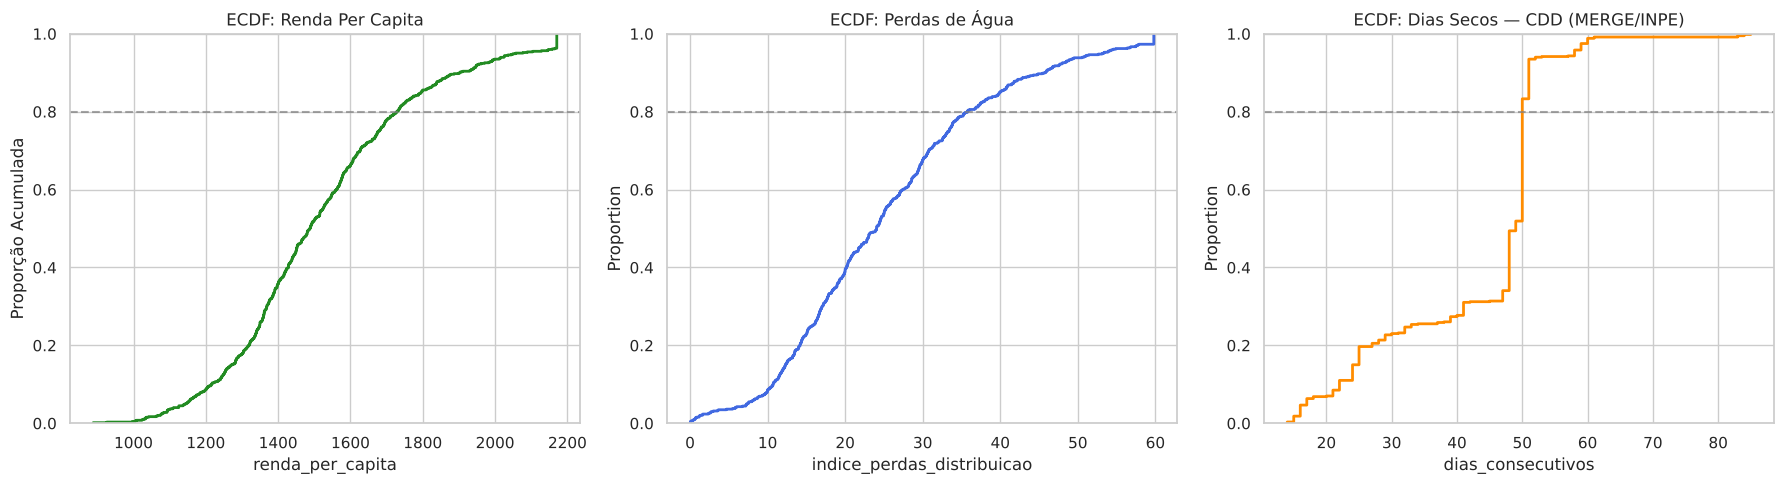

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ECDF Renda
sns.ecdfplot(data=df_renda, x='renda_per_capita', ax=axes[0], color='forestgreen', lw=2)
axes[0].set_title('ECDF: Renda Per Capita')
axes[0].set_ylabel('Proporção Acumulada')
axes[0].axhline(0.8, color='gray', linestyle='--', alpha=0.7)

# ECDF Perdas
sns.ecdfplot(data=df_agua, x='indice_perdas_distribuicao', ax=axes[1], color='royalblue', lw=2)
axes[1].set_title('ECDF: Perdas de Água')
axes[1].axhline(0.8, color='gray', linestyle='--', alpha=0.7)

# ECDF Clima 
sns.ecdfplot(data=df_clima, x='dias_consecutivos', ax=axes[2], color='darkorange', lw=2)
axes[2].set_title('ECDF: Dias Secos — CDD (MERGE/INPE)')
axes[2].axhline(0.8, color='gray', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


### Interpretação da distribuição acumulada

A renda e as perdas acumulam a maior parte dos casos em níveis baixos e intermediários. Nas duas curvas, o último trecho é um degrau no valor do capping (renda R$ 2.171; perdas 59,8%).

A curva de dias secos (MERGE/INPE) sobe de forma abrupta em torno de 48 a 50 dias: a mediana é 49 e o terceiro quartil é 50, ou seja, a maior parte dos municípios compartilha valores de CDD muito próximos, e cerca de 94% têm CDD de até 55 dias. A parte inicial da curva (15 a 30 dias) corresponde ao grupo de baixa exposição à seca, no sul e no litoral. A cobertura espacial contínua do satélite capta esse contraste regional melhor do que as estações pontuais do INMET.

## 11. Padronização das categorias jurídicas

Esta célula substitui descrições longas de natureza jurídica por categorias mais curtas e consistentes. O objetivo é facilitar a leitura das tabelas e dos gráficos comparativos.

In [11]:
mapeamento_juridico = {
    'Sociedade de economia mista com administração pública': 'Soc. Econ. Mista com Adm. Púb.', # Pega o valor atual e altera para o novo
    'Administração pública direta': 'Adm. Púb. Direta'
}

df_agua['natureza_juridica'] = df_agua['natureza_juridica'].replace(mapeamento_juridico)

### Interpretação da padronização jurídica

As categorias de natureza jurídica foram simplificadas para facilitar a leitura das tabelas e gráficos.

## 12. Perdas por natureza jurídica

Esta célula agrupa as perdas de água por natureza jurídica e apresenta médias, medianas, contagens e um gráfico de violino. O objetivo é comparar o desempenho dos diferentes modelos de gestão.

'Perdas de Água agrupadas por Natureza Jurídica do Prestador:'

,mean,median,count
natureza_juridica,,,
Autarquia,33.90,33.54,84
Empresa privada,28.25,27.72,28
Adm. Púb. Direta,26.47,23.28,141
Soc. Econ. Mista com Adm. Púb.,23.24,22.03,379
Empresa pública,23.04,23.04,1


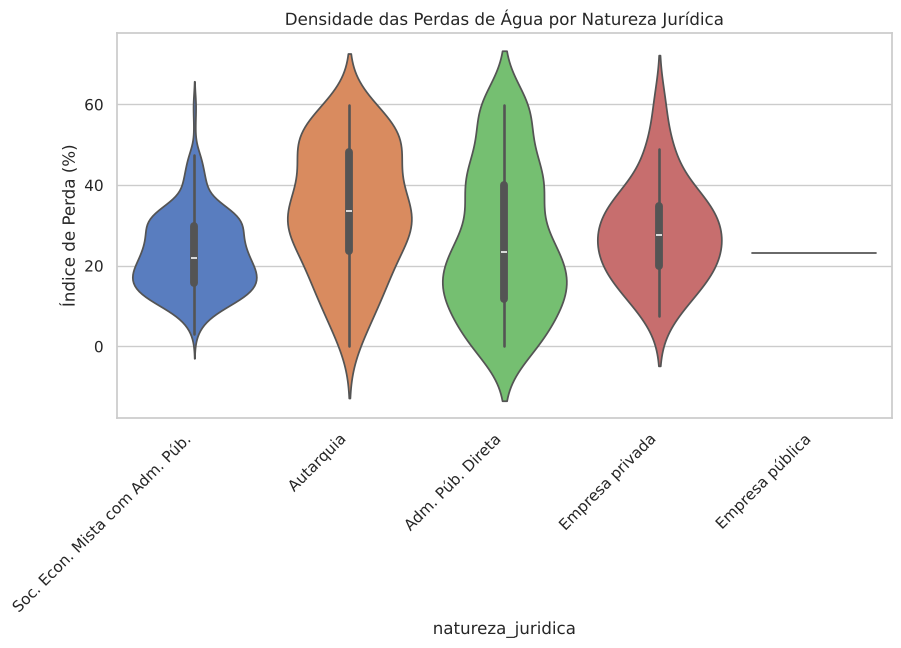

In [12]:

# analisando a perda media de agua pelo tipo de Natureza Jurídica do prestador
agrupamento_juridico = df_agua.groupby('natureza_juridica')['indice_perdas_distribuicao'].agg(['mean', 'median', 'count']).sort_values(by='mean', ascending=False)
display("Perdas de Água agrupadas por Natureza Jurídica do Prestador:", agrupamento_juridico.round(2))

# grafico de violino (um boxplot que mostra a densidade basicamente)
plt.figure(figsize=(10, 5))
sns.violinplot(data=df_agua, x='natureza_juridica', y='indice_perdas_distribuicao', palette='muted')
plt.title('Densidade das Perdas de Água por Natureza Jurídica')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Índice de Perda (%)')
plt.show()

### Interpretação das perdas por natureza jurídica

As maiores perdas médias aparecem entre as **autarquias**, com média de **33,90%**, seguidas pelas empresas privadas, com **28,25%**, e pela administração pública direta, com **26,47%**. As sociedades de economia mista com administração pública apresentam média de **23,24%**, a menor entre os grupos com quantidade relevante de observações.

A comparação deve considerar também o tamanho das amostras: sociedades de economia mista possuem 379 registros, administração pública direta 141, autarquias 84 e empresas privadas 28. A categoria empresa pública possui apenas 1 registro e não permite uma conclusão geral. A administração direta tem 141 registros (e não 150) porque 9 prefeituras reportaram perdas de 0,00%, tratadas como dado ausente (seção 4.1). O gráfico de violino mostra que a dispersão varia entre os modelos de gestão.

## 13. Rankings de perdas e renda

Esta célula lista os municípios com maiores perdas de água e menores rendas per capita.

In [13]:
display("Top 5 Municípios com MAIOR perda de água (valores brutos, antes do capping):", 
        df_agua_bruto[['municipio', 'indice_perdas_distribuicao', 'prestador']].sort_values(by='indice_perdas_distribuicao', ascending=False).head())

display("Top 5 Municípios com MENOR renda per capita:", 
        df_renda[['municipio', 'renda_per_capita']].sort_values(by='renda_per_capita', ascending=True).head())

'Top 5 Municípios com MAIOR perda de água (valores brutos, antes do capping):'

,municipio,indice_perdas_distribuicao,prestador
364,Natividade da Serra,89.63,Prefeitura Municipal de Natividade da Serra
334,Mendonça,80.08,Prefeitura Municipal de Mendonça
457,Potim,76.58,Águas de Potim SPE LTDA
241,Ipaussu,76.35,Prefeitura Municipal de Ipaussu
119,Capivari,75.39,Serviço Autônomo de Água e Esgoto


'Top 5 Municípios com MENOR renda per capita:'

,municipio,renda_per_capita
60,Barra do Chapéu (SP),888.50
368,Nova Campina (SP),926.06
91,Buri (SP),996.87
577,Sete Barras (SP),1004.06
253,Itaoca (SP),1008.01


### Interpretação dos rankings

Os maiores índices de perdas (valores brutos, antes do capping) foram observados em **Natividade da Serra (89,63%)**, **Mendonça (80,08%)**, **Potim (76,58%)**, **Ipaussu (76,35%)** e **Capivari (75,39%)**.

Os menores valores de renda per capita foram encontrados em **Barra do Chapéu (R$ 888,50)**, **Nova Campina (R$ 926,06)**, **Buri (R$ 996,87)**, **Sete Barras (R$ 1.004,06)** e **Itaoca (R$ 1.008,01)**.

## 14. Comparação das perdas por características do serviço

Esta célula compara a perda média por natureza jurídica, abrangência e tipo de serviço. O objetivo é identificar padrões de eficiência entre diferentes configurações de saneamento.

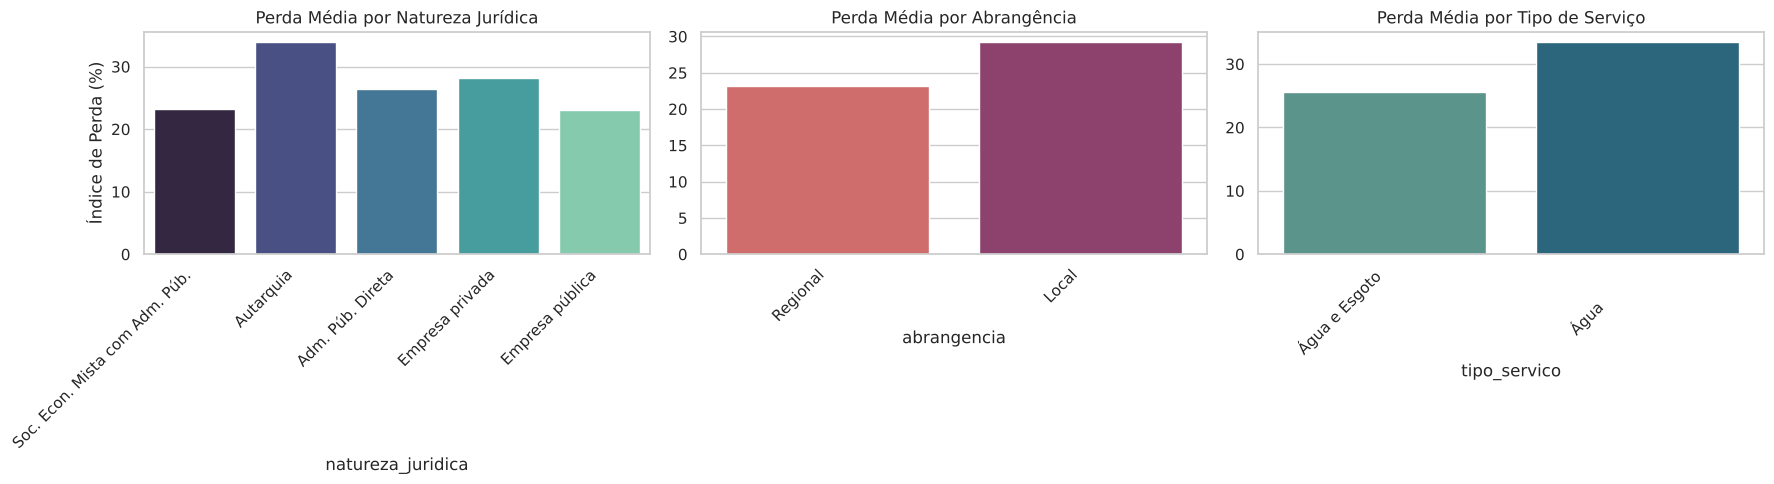

'Top 5 Prestadores de Saneamento (Qtd de Municípios Atendidos):'

sigla_prestador
SABESP    375
SAAE       31
PMI        11
PMC         9
PMP         9
Name: count, dtype: int64

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Perda x Natureza Jurídica
sns.barplot(data=df_agua, x='natureza_juridica', y='indice_perdas_distribuicao', errorbar=None, palette='mako', ax=axes[0])
axes[0].set_title('Perda Média por Natureza Jurídica')
axes[0].tick_params(axis='x', labelrotation=45)
plt.setp(axes[0].get_xticklabels(), ha='right')
axes[0].set_ylabel('Índice de Perda (%)')

# Perda x Abrangência
sns.barplot(data=df_agua, x='abrangencia', y='indice_perdas_distribuicao', errorbar=None, palette='flare', ax=axes[1])
axes[1].set_title('Perda Média por Abrangência')
axes[1].tick_params(axis='x', labelrotation=45)
plt.setp(axes[1].get_xticklabels(), ha='right')
axes[1].set_ylabel('')

# Perda x Tipo de Serviço
sns.barplot(data=df_agua, x='tipo_servico', y='indice_perdas_distribuicao', errorbar=None, palette='crest', ax=axes[2])
axes[2].set_title('Perda Média por Tipo de Serviço')
axes[2].tick_params(axis='x', labelrotation=45)
plt.setp(axes[2].get_xticklabels(), ha='right')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

display("Top 5 Prestadores de Saneamento (Qtd de Municípios Atendidos):")
display(df_agua['sigla_prestador'].value_counts().head())

### Interpretação das comparações por serviço

A SABESP lidera isoladamente com ampla vantagem, atendendo 375 municípios, seguida por autarquias municipais como o SAAE (31 cidades), evidenciando a dualidade entre grandes operadoras regionais e serviços autônomos locais.

As autarquias registram a maior média de perdas de água no estado (~34%), enquanto as empresas públicas e sociedades de economia mista apresentam os menores índices médios (cerca de 23%).

Prestadores com abrangência Regional apresentam perdas médias inferiores (~23,1%) em relação aos de abrangência Local (~29,2%), sugerindo ganhos de eficiência operacional em redes integradas.

Redes dedicadas exclusivamente ao serviço de Água têm perdas médias maiores (~33,4%) do que as que operam o sistema combinado de Água e Esgoto (~25,6%), mas a categoria "Água" tem apenas 3 municípios, e a comparação deve ser lida com cautela.

## 15. Integração entre clima e perdas de água

Esta célula cria uma chave municipal compatível, cruza as bases climática, de perdas e de renda e prepara o DataFrame `df_final`. O objetivo é reunir os indicadores necessários para as análises multivariadas.

In [15]:
# df_clima usa 'id' (7 digitos IBGE, oriundo do GeoJSON); os demais usam 'id_municipio'.
# todos são truncados para 6 digitos para compatibilidade.
df_clima['_chave_merge'] = df_clima['id'].astype('string').str.strip().str[:6]
df_agua['_chave_merge'] = df_agua['id_municipio'].astype('string').str.strip().str[:6]
df_renda['_chave_merge'] = df_renda['id_municipio'].astype('string').str.strip().str[:6]

# Removendo duplicatas
df_clima_limpo = df_clima.drop_duplicates(subset=['_chave_merge'])
df_agua_limpo = df_agua.drop_duplicates(subset=['_chave_merge'])
df_renda_limpo = df_renda.drop_duplicates(subset=['_chave_merge'])

display("Top 10 Cidades mais suscetíveis à seca (Maiores valores de CDD — MERGE/INPE):")
display(df_clima_limpo[['name', 'dias_consecutivos']].sort_values(by='dias_consecutivos', ascending=False).head(10))

# merge final
df_final = (
    df_agua_limpo[
        [
            '_chave_merge',
            'id_municipio',
            'municipio',
            'abrangencia',
            'natureza_juridica',
            'tipo_servico',
            'indice_perdas_distribuicao'
        ]
    ]
    .merge(
        df_renda_limpo[['_chave_merge', 'renda_per_capita']],
        on='_chave_merge',
        how='outer'
    )
    .merge(
        df_clima_limpo[['_chave_merge', 'dias_consecutivos']],
        on='_chave_merge',
        how='left'
    )
    .drop(columns='_chave_merge')
)

cidades_criticas = (df_final['dias_consecutivos'] > 30).sum()
municipios_sem_clima = df_final['dias_consecutivos'].isna().sum()
print(f"\nMunicípios com mais de 30 dias secos seguidos: {cidades_criticas}")
print(f"Registros sem dado climático (receberão imputação espacial na seção 25): {municipios_sem_clima}")
print(f"Municípios integrados em df_final: {len(df_final)}")


'Top 10 Cidades mais suscetíveis à seca (Maiores valores de CDD — MERGE/INPE):'

,name,dias_consecutivos
31,Aramina,85
61,Batatais,84
468,Sales Oliveira,84
261,Jardinópolis,83
357,Orlândia,83
308,Miguelópolis,61
495,Santa Rosa de Viterbo,61
85,Buritizal,60
248,Itirapuã,60
15,Alvinlândia,60



Municípios com mais de 30 dias secos seguidos: 461
Registros sem dado climático (receberão imputação espacial na seção 25): 46
Municípios integrados em df_final: 645


### Interpretação da integração das bases

O *merge* (`outer`) gerou **645 registros**: **633 municípios** com perdas de água válidas no SNIS e **12 registros presentes apenas na base de renda**, sem correspondência na base de perdas (por isso sem `id_municipio` e `municipio`): 2 municípios sem informação do SNIS e os 10 com perdas de 0,00%, excluídos na seção 4.1. Esses 12 registros são removidos na etapa 25, e a **base final tem 633 municípios**.

A base climática (MERGE/INPE) tem dado para 599 dos 645 municípios da malha do IBGE. Desses, **587 estão entre os 633 municípios da base final**; os **46 restantes** não têm dado climático e receberão imputação espacial na etapa 25 (587 + 46 = 633).

A contagem de **461 registros com mais de 30 dias consecutivos secos** foi feita sobre o resultado bruto do *merge* (645 registros, antes da remoção dos 12 registros sem perdas válidas). O top 10 de CDD é liderado por Aramina (85 dias), Batatais e Sales Oliveira (84 dias) e Jardinópolis e Orlândia (83 dias), todos localizados na região nordeste do estado.

A chave temporária de seis dígitos (`_chave_merge`) foi removida ao final, mantendo apenas os identificadores originais de cada base.

## 16. Análise de Dispersão Multivariada por Abrangência do Saneamento

Este código tem o objetivo de gerar uma matriz de gráficos de dispersão e densidade para analisar simultaneamente as interações entre a renda per capita, o índice de perdas de água e o máximo de dias secos, segmentando as observações pela abrangência do serviço de saneamento (local ou regional). Com essa visualização, é possível inspecionar de forma cruzada o comportamento e a distribuição conjunta dessas variáveis no estado.

<Figure size 1200x1000 with 0 Axes>

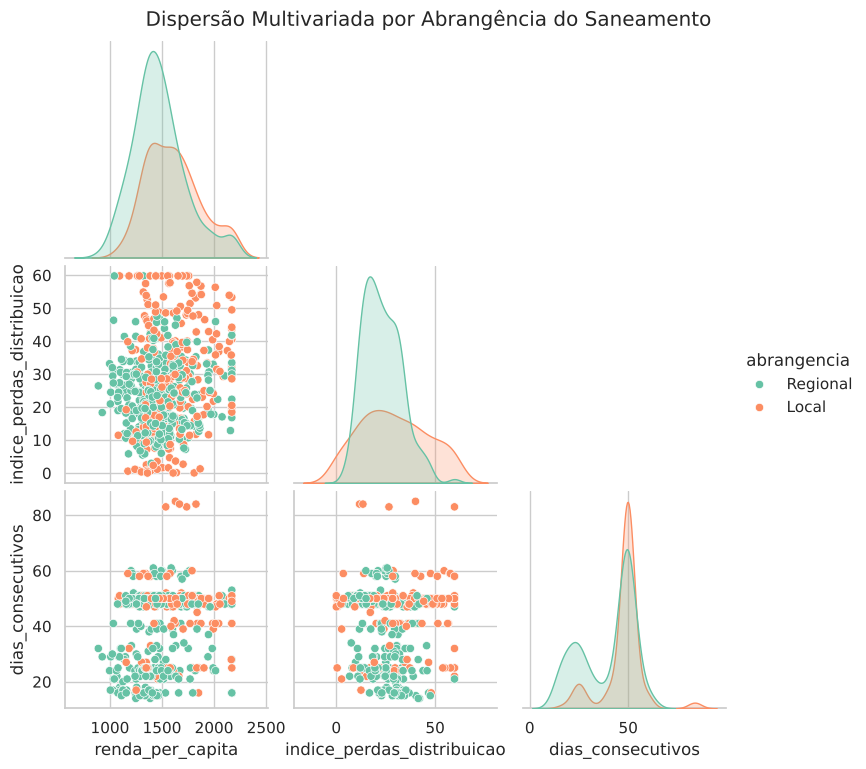

In [16]:
colunas_pairplot = ['renda_per_capita', 'indice_perdas_distribuicao', 'dias_consecutivos', 'abrangencia']

plt.figure(figsize=(12, 10))
sns.pairplot(df_final[colunas_pairplot], hue='abrangencia', palette='Set2', diag_kind='kde', corner=True)
plt.suptitle('Dispersão Multivariada por Abrangência do Saneamento', y=1.02)
plt.show()


### Interpretação do pairplot

Os grupos de abrangência Regional e Local ocupam faixas semelhantes de renda. No índice de perdas, os prestadores Regionais concentram-se entre ~10% e 30%, enquanto os Locais têm uma dispersão bem mais larga, com cauda até 60%.

Nas diagonais, a renda e as perdas têm distribuições unimodais assimétricas, mas o CDD é **bimodal**: um grupo em torno de 20 a 25 dias e outro, dominante, em torno de 50 dias. Os 5 municípios com CDD acima de 80 dias são todos de abrangência Local.

## 17. Análise de Correlação entre Renda Per Capita e Eficiência do Saneamento

Este código tem o objetivo de examinar a relação estatística e o ajuste de regressão linear entre a renda per capita dos municípios e o índice de perdas de distribuição de água. A visualização combina um diagrama de dispersão com curvas de densidade marginais (histogramas), permitindo avaliar simultaneamente a tendência central e a distribuição isolada de cada indicador no estado.

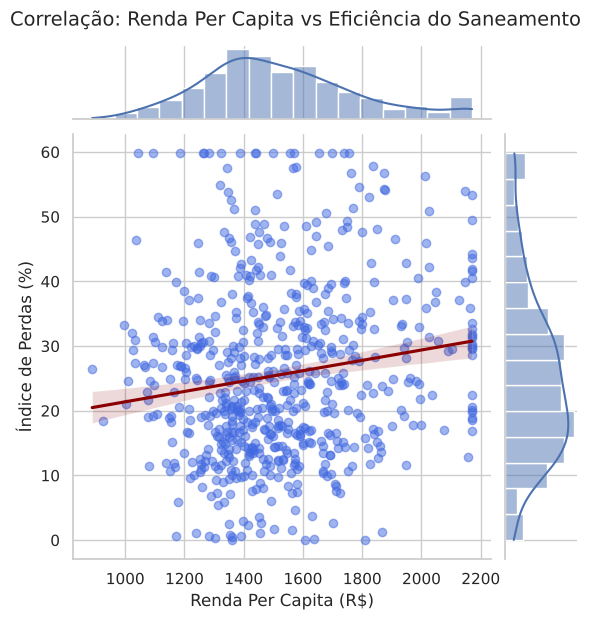

In [17]:
# Criando o jointplot e armazenando em uma variável 'g'
g = sns.jointplot(
    data=df_final, 
    x='renda_per_capita', 
    y='indice_perdas_distribuicao', 
    kind='reg', 
    scatter_kws={'alpha': 0.5, 'color': 'royalblue'}, 
    line_kws={'color': 'darkred'}
)

# Ajustando o título corretamente utilizando a API do JointGrid para evitar sobreposições
g.fig.suptitle('Correlação: Renda Per Capita vs Eficiência do Saneamento', y=1.03, fontsize=14)
g.set_axis_labels('Renda Per Capita (R$)', 'Índice de Perdas (%)', fontsize=12)

plt.show()

### Interpretação da relação entre renda e perdas

A linha de tendência exibe uma inclinação positiva leve, indicando que municípios com maior renda per capita apresentam, em média, perdas ligeiramente maiores (correlação de Spearman de 0,15, fraca). A faixa de confiança da reta mostra que a relação é pouco precisa.

Os histogramas marginais mostram que a renda se concentra entre R$ 1.200 e R$ 1.800 (com um acúmulo no teto do capping, R$ 2.171) e que as perdas se concentram entre 10% e 35%, com um segundo acúmulo no teto de 59,8%.

## 18. Matriz de Média de Perdas por Natureza Jurídica e Tipo de Serviço

Este código tem o objetivo de estruturar e visualizar uma tabela dinâmica em formato de mapa de calor (heatmap) cruzando a natureza jurídica dos prestadores com o tipo de serviço prestado. O gráfico exibe os valores médios do índice de perdas de água para cada categoria, permitindo identificar quais modelos de gestão e escopos de atendimento apresentam maior ou menor eficiência hídrica no estado.

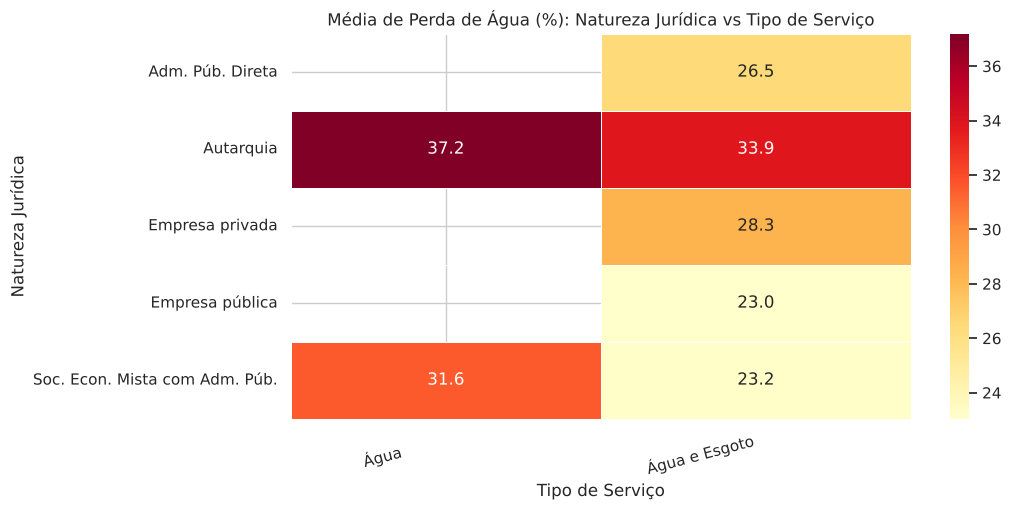

In [18]:
# Cria uma tabela dinâmica calculando a média de perda de água para cada cruzamento
tabela_cruzada = pd.pivot_table(
    data=df_final, 
    values='indice_perdas_distribuicao', 
    index='natureza_juridica', 
    columns='tipo_servico', 
    aggfunc='mean'
)

plt.figure(figsize=(10, 5))
sns.heatmap(tabela_cruzada, annot=True, cmap='YlOrRd', fmt=".1f", linewidths=0.5)
plt.title('Média de Perda de Água (%): Natureza Jurídica vs Tipo de Serviço')
plt.ylabel('Natureza Jurídica')
plt.xlabel('Tipo de Serviço')
plt.xticks(rotation=15, ha='right')
plt.show()

### Interpretação do mapa de calor

As autarquias dedicadas exclusivamente ao serviço de água apresentam a maior taxa média de perdas do estado (37,2%), mas esse valor vem de **1 único município**; na prestação conjunta de "Água e Esgoto", as autarquias têm 33,9% (83 municípios).

As empresas públicas e sociedades de economia mista na prestação conjunta de "Água e Esgoto" registram os menores índices médios (23,0% e 23,2%, a primeira com apenas 1 município), sugerindo maior eficiência nesses arranjos. As sociedades de economia mista que prestam só o serviço de água têm 31,6% (2 municípios).

Os espaços em branco na matriz representam cruzamentos que não existem na base.

## 19. Zonas de Densidade Bivariada: Risco Climático e Ineficiência Operacional

Este código tem o objetivo de gerar um gráfico de densidade bivariada (2D KDE com preenchimento em formato de contorno) para mapear a concentração de municípios em função de sua exposição a períodos de seca extrema (CDD) e do índice de perdas na distribuição de água. A visualização permite identificar visualmente as zonas de maior aglomeração de cidades que compartilham níveis semelhantes de vulnerabilidade climática e ineficiência operacional no saneamento.

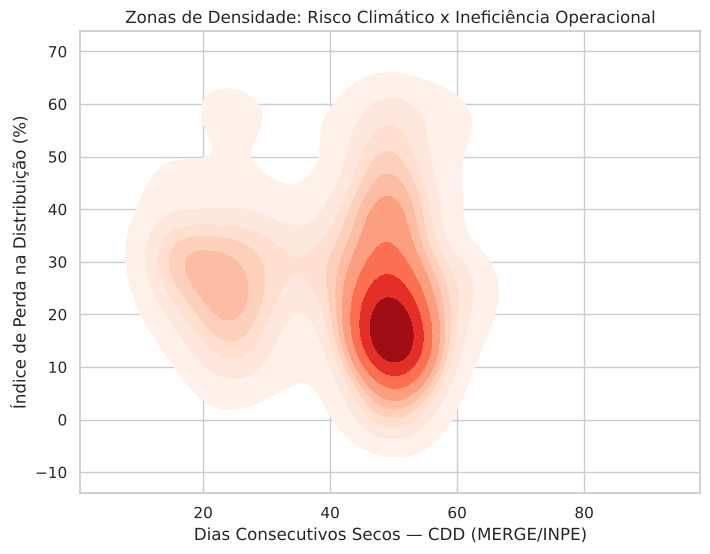

In [19]:
plt.figure(figsize=(8, 6))
sns.kdeplot(
    data=df_final, 
    x='dias_consecutivos', 
    y='indice_perdas_distribuicao', 
    fill=True, 
    cmap='Reds', 
    thresh=0.05
)
plt.title('Zonas de Densidade: Risco Climático x Ineficiência Operacional')
plt.xlabel('Dias Consecutivos Secos — CDD (MERGE/INPE)')
plt.ylabel('Índice de Perda na Distribuição (%)')
plt.show()


### Interpretação da densidade bivariada

A densidade tem **dois núcleos**. O principal e mais escuro (vermelho profundo) fica em torno de 50 dias consecutivos secos e perdas de 15% a 20%, onde se concentra a maioria dos municípios paulistas. Um segundo núcleo, mais fraco, aparece em torno de 20 a 25 dias de CDD, com perdas de 25% a 30%, e corresponde ao grupo de baixa exposição à seca.

As caudas se estendem em direção a perdas maiores (acima de 50%) em ambos os núcleos. As bordas do gráfico incluem valores negativos de perdas e CDD acima de 70 dias apenas por efeito de suavização da estimativa de densidade; não há dados nessas regiões.

## 20. Gráfico de Dispersão Tridimensional da Vulnerabilidade Hídrica

Este código tem o objetivo de construir um gráfico de dispersão em 3D para mapear simultaneamente as três dimensões centrais da vulnerabilidade municipal: renda per capita no eixo X, índice de perdas de água no eixo Y e dias consecutivos secos no eixo Z. A visualização utiliza uma paleta de cores contínua baseada no nível de perdas para realçar a intensidade da ineficiência operacional ao longo do espaço tridimensional das variáveis.

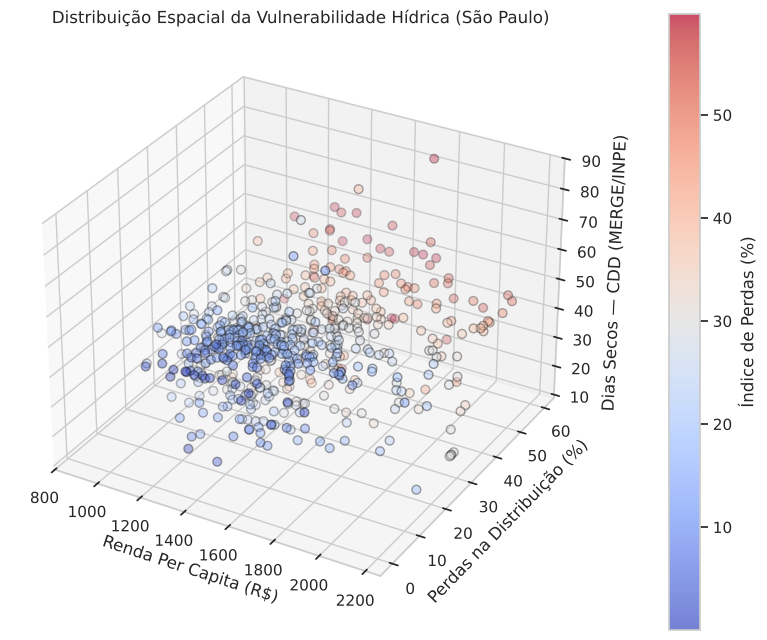

In [20]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Eixos x (Renda), y (Perda), z (Clima)
x = df_final['renda_per_capita']
y = df_final['indice_perdas_distribuicao']
z = df_final['dias_consecutivos']

# O mapa de cores (cmap) reforça visualmente o eixo da ineficiência
scatter = ax.scatter(x, y, z, c=y, cmap='coolwarm', alpha=0.7, s=40, edgecolors='k')

ax.set_xlabel('Renda Per Capita (R$)')
ax.set_ylabel('Perdas na Distribuição (%)')
ax.set_zlabel('Dias Secos — CDD (MERGE/INPE)')
ax.set_title('Distribuição Espacial da Vulnerabilidade Hídrica (São Paulo)')

plt.colorbar(scatter, label='Índice de Perdas (%)', pad=0.1)
plt.show()


### Interpretação do gráfico 3D

Os municípios se organizam em duas camadas de CDD: uma em torno de 15 a 30 dias e outra, maior, em torno de 45 a 60 dias, com poucos municípios acima disso. A renda concentra-se na faixa de R$ 1.200 a R$ 2.000 nas duas camadas.

Os altos índices de perdas (tons avermelhados) aparecem espalhados pelas duas camadas e por toda a faixa de renda, sem um padrão simples: a correlação de Spearman entre perdas e CDD é fraca (−0,23) e a entre perdas e renda é de 0,15. Isso mostra que as três variáveis trazem informação complementar, o que sustenta o uso conjunto delas na clusterização.

## 21. Teste Estatístico de Kruskal-Wallis entre Perdas e Natureza Jurídica

Este código tem o objetivo de aplicar o teste não paramétrico de Kruskal-Wallis para verificar se existem diferenças estatisticamente significativas nos índices de perdas de água entre os municípios, agrupando-os conforme a natureza jurídica de seus prestadores de saneamento. A rotina separa as amostras por categoria de gestão, calcula a estatística $H$ e o $p$-valor correspondente, e emite uma conclusão automática para subsidiar a validação das hipóteses do estudo.

In [21]:
# Filtra os dados removendo categorias vazias ou muito pequenas
df_teste = df_final.dropna(subset=['natureza_juridica', 'indice_perdas_distribuicao'])
categorias = [grupo['indice_perdas_distribuicao'].values for nome, grupo in df_teste.groupby('natureza_juridica')]

# Aplica o teste de Kruskal-Wallis
estatistica, p_valor = stats.kruskal(*categorias)

print("=== Teste de Kruskal-Wallis (Perdas vs Natureza Jurídica) ===")
print(f"Estatística H: {estatistica:.2f}")
print(f"P-valor: {p_valor:.4e}")

if p_valor < 0.05:
    print("-> Conclusão: Há diferença estatisticamente significativa nas perdas de água entre os diferentes tipos de gestão.")
else:
    print("-> Conclusão: Não há evidências de que o tipo de gestão afeta significativamente as perdas.")

=== Teste de Kruskal-Wallis (Perdas vs Natureza Jurídica) ===
Estatística H: 35.09
P-valor: 4.4451e-07
-> Conclusão: Há diferença estatisticamente significativa nas perdas de água entre os diferentes tipos de gestão.


### Interpretação do teste de Kruskal-Wallis

O teste apresentou estatística **H = 35,09** e **p-valor = 4,4451 × 10⁻⁷**. Como o p-valor é menor que 0,05, rejeita-se a hipótese de que todos os grupos de natureza jurídica possuem a mesma distribuição de perdas.

Assim, há evidência estatística de diferença nas perdas de água entre os modelos de gestão. O teste identifica que existe diferença entre pelo menos dois grupos, mas não informa quais pares são diferentes; uma análise pós-hoc seria necessária para localizar essas diferenças. O teste inclui a categoria "Empresa pública", que tem apenas 1 município.

## 22. Renderização Cartográfica Tripla da Vulnerabilidade Municipal

Este código tem o objetivo de baixar a malha geográfica vetorial oficial do estado de São Paulo diretamente da API do IBGE, padronizar as chaves de identificação municipal e realizar a junção espacial (left join) com a base de dados consolidada. Em seguida, o script gera um painel cartográfico composto por três mapas coropléticos lado a lado, representando a distribuição espacial da renda per capita, do índice de perdas de água e do risco climático de seca no estado.

Baixando malha completa de SP do IBGE...


API do IBGE indisponível (ProxyError); usando a malha alternativa.
Malha utilizada: geodata-br (códigos IBGE)
Municípios na malha: 645
Municípios com dados de renda integrados: 633
Municípios com dados climáticos integrados: 587


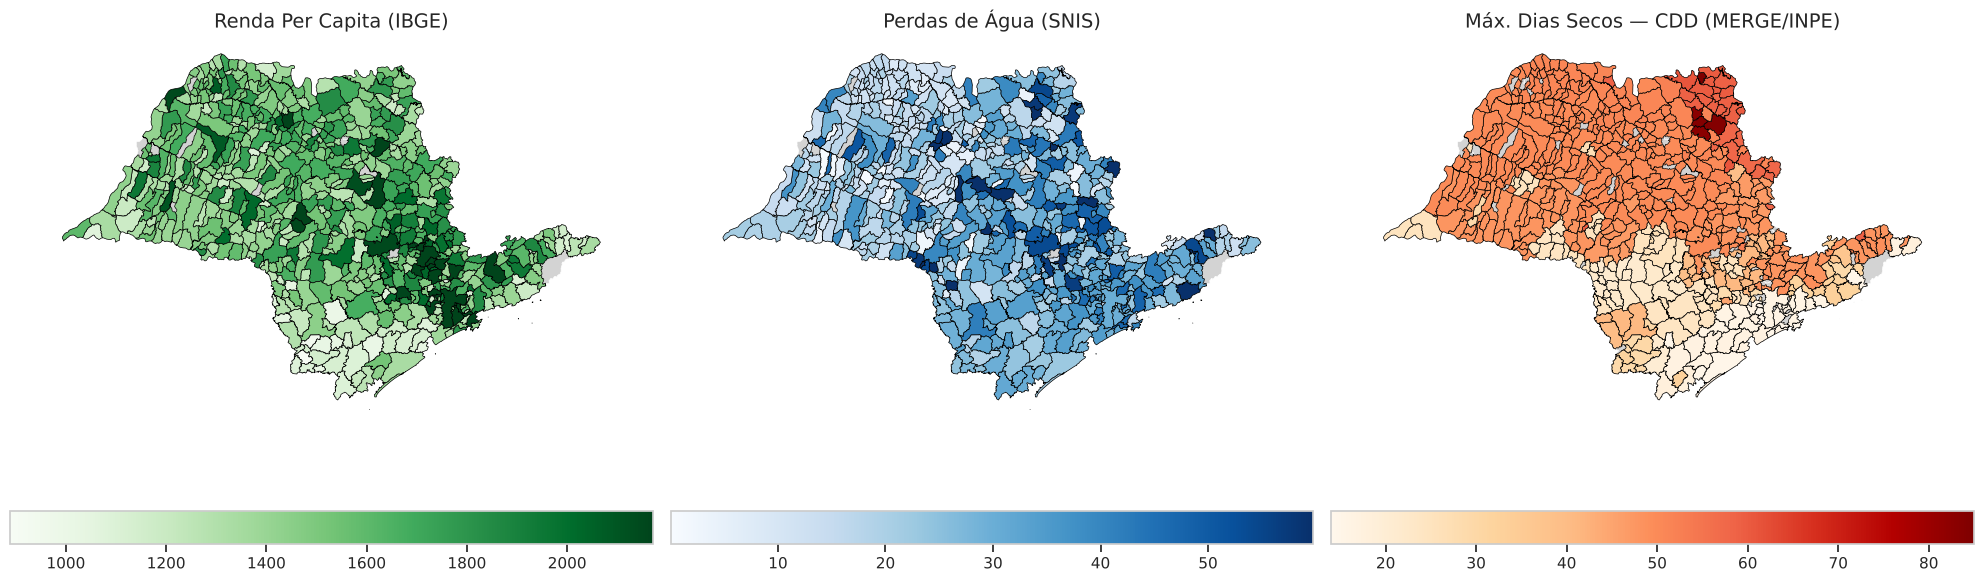

In [22]:
# 1. Malha municipal de SP. Fonte principal: API de malhas do IBGE. Se a API estiver indisponível (rede, proxy),
#    usa a mesma malha (códigos IBGE de 7 dígitos) do repositório público tbrugz/geodata-br, em cópia local ou via GitHub.
url_todas_cidades_sp = "https://servicodados.ibge.gov.br/api/v3/malhas/estados/35?resolucao=5&intrarregiao=municipio&formato=application/vnd.geo+json"
ARQ_MALHA = 'geojs-35-mun.json'
URL_MALHA_GITHUB = 'https://raw.githubusercontent.com/tbrugz/geodata-br/master/geojson/geojs-35-mun.json'

def carregar_malha_sp():
    try:
        print("Baixando malha completa de SP do IBGE...")
        resposta = requests.get(url_todas_cidades_sp, timeout=60)
        resposta.raise_for_status()
        return gpd.GeoDataFrame.from_features(resposta.json()["features"], crs='EPSG:4326'), 'API de malhas do IBGE'
    except Exception as erro:
        print(f"API do IBGE indisponível ({type(erro).__name__}); usando a malha alternativa.")
        g = gpd.read_file(ARQ_MALHA if os.path.exists(ARQ_MALHA) else URL_MALHA_GITHUB)
        g = g.rename(columns={'id': 'codarea'})[['codarea', 'geometry']]
        g['geometry'] = g.geometry.buffer(0)          # corrige geometrias inválidas (auto-interseções)
        return g, 'geodata-br (códigos IBGE)'

# 2. Conversão segura para GeoDataFrame
mapa_sp, FONTE_MALHA = carregar_malha_sp()
mapa_sp['codarea'] = mapa_sp['codarea'].astype(str)
print(f"Malha utilizada: {FONTE_MALHA}")

# 3. Padronização da chave de união
mapa_sp['id_join'] = mapa_sp['codarea'].astype(str).str[:6]
df_final['id_join'] = df_final['id_municipio'].astype(str).str[:6]

# 4. Merge Left
mapa_dados = mapa_sp.merge(df_final, on='id_join', how='left')

print(f"Municípios na malha: {len(mapa_sp)}")
print(f"Municípios com dados de renda integrados: {mapa_dados['renda_per_capita'].notna().sum()}")
print(f"Municípios com dados climáticos integrados: {mapa_dados['dias_consecutivos'].notna().sum()}")

# 5. Renderizando os mapas
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax in axes:
    ax.axis('off')

# Mapa 1: Renda
mapa_dados.plot(ax=axes[0], color='lightgrey', edgecolor='white', linewidth=0.4)
mapa_dados.dropna(subset=['renda_per_capita']).plot(
    column='renda_per_capita', cmap='Greens', linewidth=0.5, edgecolor='black',
    legend=True, legend_kwds={'orientation': "horizontal"}, ax=axes[0]
)
axes[0].set_title('Renda Per Capita (IBGE)', fontsize=14)

# Mapa 2: Perdas
mapa_dados.plot(ax=axes[1], color='lightgrey', edgecolor='white', linewidth=0.4)
mapa_dados.dropna(subset=['indice_perdas_distribuicao']).plot(
    column='indice_perdas_distribuicao', cmap='Blues', linewidth=0.5, edgecolor='black',
    legend=True, legend_kwds={'orientation': "horizontal"}, ax=axes[1]
)
axes[1].set_title('Perdas de Água (SNIS)', fontsize=14)

# Mapa 3: Clima (CDD — satélite MERGE/INPE)
mapa_dados.plot(ax=axes[2], color='lightgrey', edgecolor='white', linewidth=0.4)
mapa_dados.dropna(subset=['dias_consecutivos']).plot(
    column='dias_consecutivos', cmap='OrRd', linewidth=0.5, edgecolor='black',
    legend=True, legend_kwds={'orientation': "horizontal"}, ax=axes[2]
)
axes[2].set_title('Máx. Dias Secos — CDD (MERGE/INPE)', fontsize=14)

plt.tight_layout()
plt.show()


### Interpretação dos mapas temáticos

A malha municipal contém **645 municípios**, dos quais **633 possuem dados integrados** (renda e perdas de água) e **587 possuem dado climático medido** pelo satélite MERGE/INPE. Aparecem em cinza os municípios sem dado: 12 sem perdas válidas (2 sem informação do SNIS e 10 com perdas de 0,00%), nos três mapas, e os 46 sem pixel de precipitação, no mapa de CDD.

A comparação espacial evidencia que os três indicadores têm distribuições geográficas distintas: a renda é menor no Vale do Ribeira e no sul/sudoeste do estado e maior na região metropolitana de São Paulo e em Campinas; as perdas aparecem de forma dispersa no território, com concentração maior no centro-leste; e o CDD mostra um **gradiente norte-sul** nítido, com valores baixos (abaixo de ~30 dias) no sul e no litoral, altos (45 dias ou mais) no interior e máximos no nordeste do estado (região de Ribeirão Preto).

## 23. Mapeamento Categórico dos Modelos de Gestão de Saneamento

Este código tem o objetivo de renderizar um mapa coroplético unificado do estado de São Paulo, destacando a distribuição geográfica dos diferentes modelos de gestão de saneamento de acordo com a natureza jurídica dos prestadores. A rotina utiliza uma camada base em cinza claro para preencher todo o território municipal e sobrepõe os dados categóricos utilizando uma paleta de cores distinta (tab10) para evitar conflitos visuais e assegurar a legibilidade das legendas.

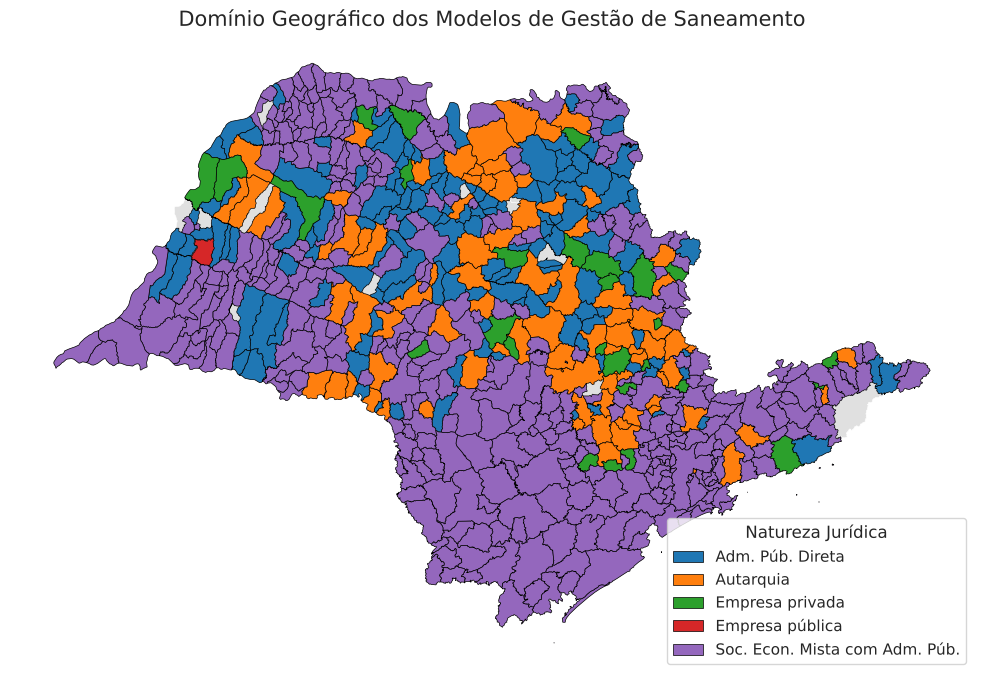

,Quantidade (Municípios),Porcentagem (%)
natureza_juridica,,
Soc. Econ. Mista com Adm. Púb.,379,59.87
Adm. Púb. Direta,141,22.27
Autarquia,84,13.27
Empresa privada,28,4.42
Empresa pública,1,0.16


In [23]:
fig, ax = plt.subplots(1, 1, figsize=(10, 8))
ax.axis('off')

# 1. Camada Base: Fundo do estado em cinza bem clarinho
mapa_dados.plot(ax=ax, color='#e0e0e0', edgecolor='white', linewidth=0.4)

# 2. Camada de Dados: Usando a paleta 'tab10' para evitar o cinza
mapa_dados.dropna(subset=['natureza_juridica']).plot(
    column='natureza_juridica', 
    categorical=True, 
    cmap='tab10', # <-- Troca da paleta aqui
    linewidth=0.5, 
    edgecolor='black', 
    legend=True,
    legend_kwds={'loc': 'lower right', 'title': 'Natureza Jurídica'},
    ax=ax
)

ax.set_title('Domínio Geográfico dos Modelos de Gestão de Saneamento', fontsize=15)
plt.tight_layout()
plt.show()

# Calculando a contagem absoluta e a porcentagem de cada modelo de gestão
contagem = df_final['natureza_juridica'].value_counts()
porcentagem = df_final['natureza_juridica'].value_counts(normalize=True) * 100

df_distribuicao = pd.DataFrame({
    'Quantidade (Municípios)': contagem,
    'Porcentagem (%)': porcentagem.round(2)
})

display(df_distribuicao)

### Interpretação do mapa de modelos de gestão

Observa-se uma vasta predominância da Sociedade de Economia Mista com Administração Pública (roxo, onde se insere a atuação da Sabesp) cobrindo grande parte do território paulista, especialmente nas regiões sul, leste e oeste.

As autarquias (laranja) formam manchas concentradas no centro-leste do interior, e a administração pública direta (azul) aparece de forma mais dispersa no norte e no centro. As empresas privadas (verde) e a única empresa pública (vermelho) aparecem de forma pontual e isolada, evidenciando a diversidade institucional na prestação dos serviços de saneamento básico no estado. Os municípios em cinza não têm dado de perdas válido.

A tabela gerada mostra a distribuição exata:

- A Sociedade de Economia Mista com Administração Pública lidera com folga, cobrindo 59,87% dos municípios analisados, o que reflete a forte capilaridade de grandes operadoras integradas (como a Sabesp).

- As Autarquias e a Administração Pública Direta somam juntas 35,54% das cidades, demonstrando que mais de um terço dos municípios gere os serviços de saneamento por dentro da estrutura da própria administração municipal.

- As Empresas privadas representam apenas 4,42% dos municípios, enquanto a Empresa pública tem presença residual na amostra (0,16%, 1 município).

## 24. Normalização Z-Score e Comparação de Distribuições Numéricas

Este código tem o objetivo de aplicar a padronização por Z-score nas variáveis numéricas brutas do estudo: renda per capita, índice de perdas de água e máximo de dias secos. E gerar um painel gráfico comparativo de densidade (KDE). A rotina transforma as escalas originais (utilizando uma escala logarítmica no gráfico prévio para visualização) para colocar todas as dimensões em uma mesma base de desvios padrão, garantindo pesos equivalentes nas análises multivariadas e nos modelos subsequentes.

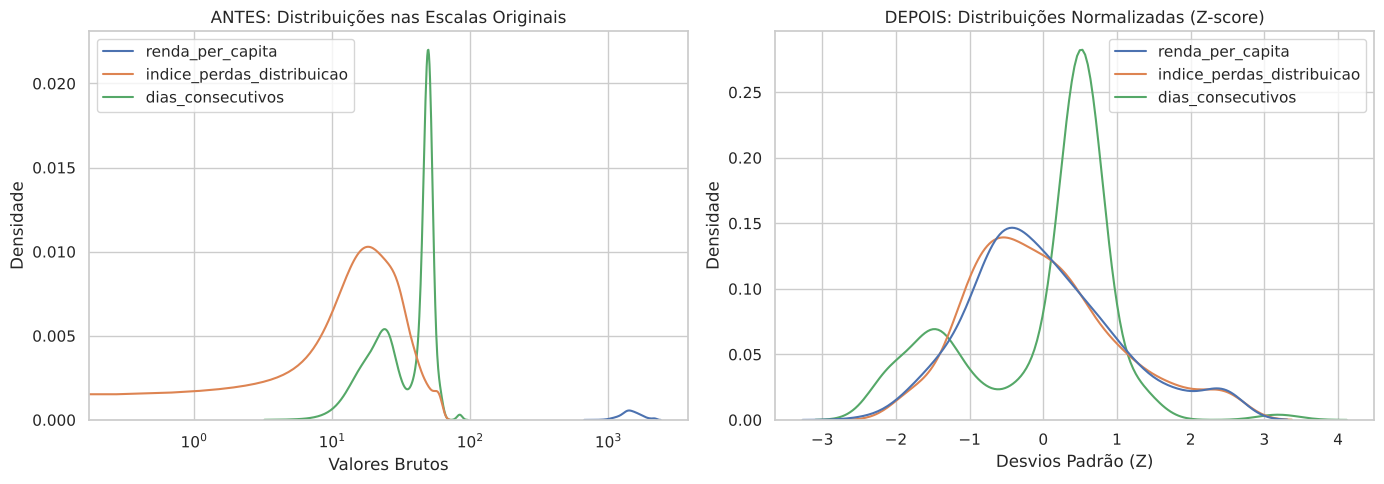

In [24]:
# Variáveis numéricas brutas
colunas = ['renda_per_capita', 'indice_perdas_distribuicao', 'dias_consecutivos']
df_bruto = df_final[colunas].dropna().copy()

# Aplicando Z-score
scaler = StandardScaler()
df_norm = pd.DataFrame(scaler.fit_transform(df_bruto), columns=colunas)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Antes da Normalização (Escalas originais)
sns.kdeplot(data=df_bruto, ax=axes[0])
axes[0].set_title('ANTES: Distribuições nas Escalas Originais')
axes[0].set_ylabel('Densidade')
axes[0].set_xlabel('Valores Brutos')
axes[0].set_xscale('log')

# Gráfico 2: Depois da Normalização (Mesma escala)
sns.kdeplot(data=df_norm, ax=axes[1])
axes[1].set_title('DEPOIS: Distribuições Normalizadas (Z-score)')
axes[1].set_ylabel('Densidade')
axes[1].set_xlabel('Desvios Padrão (Z)')

plt.tight_layout()
plt.show()


### Interpretação da normalização

A normalização por Z-score coloca renda, perdas de água e dias consecutivos secos em uma escala comum, com média próxima de zero e desvio padrão próximo de um. Isso evita que a renda, por possuir valores numericamente maiores, domine automaticamente as análises multivariadas ou os algoritmos de clusterização.

Note que o `dropna()` aplicado antes da normalização remove os 46 municípios sem dado climático do produto MERGE/INPE e os 12 registros sem perdas válidas. Esses 46 municípios são tratados com imputação espacial na seção 25, e os 12 ficam fora do modelo (seção 4.1), de modo que a base final de modelagem tem 633 municípios.

## 25. Imputação Espacial do CDD dos Municípios sem Dado Climático

A base satelital MERGE/INPE cobre **599 dos 645 municípios** da malha paulista, dos quais **587 estão na base final de 633 municípios** (que exige perdas válidas no SNIS). Os **46 municípios restantes** da base final não possuem nenhum pixel de precipitação dentro de seus limites.

Para esses casos, aplica-se **imputação espacial por inverso da distância** (IDW): o CDD de um município sem pixel é a média ponderada dos 5 municípios com CDD medido mais próximos (distância geográfica, fórmula de haversine), com peso 1/distância². A lógica é que a chuva é um fenômeno espacial, e municípios vizinhos compartilham o regime pluviométrico.

A versão anterior do notebook imputava por KNN em renda e perdas, com a ideia de que municípios parecidos socioeconomicamente teriam chuva parecida. Essa premissa não se sustenta (renda e perdas não carregam informação climática), e a validação cruzada abaixo mostra isso. O método espacial é adotado no lugar dele.

In [25]:
# ── 25.1 Base final: apenas municípios com dados do SNIS (e de renda) ────────────────────────────────
# Remove os registros que só existem na base de renda: 2 sem informação do SNIS e os 10 com perdas = 0,00% (seção 4.1).
df_final = df_final.dropna(subset=['id_municipio', 'municipio']).reset_index(drop=True)
df_final['id_municipio'] = df_final['id_municipio'].astype('int64')
df_final['chave6'] = df_final['id_municipio'].astype(str).str[:6]
assert df_final['id_municipio'].is_unique and df_final['chave6'].is_unique, 'municípios duplicados'
assert (df_final['indice_perdas_distribuicao'] > 0).all(), 'restou perda = 0,00%'
print(f'Municípios na base final: {len(df_final)}')


Municípios na base final: 633


Municípios com CDD medido pelo satélite: 587 | sem pixel (a imputar): 46
Validação cruzada (10 partes) nos 587 municípios com CDD medido | desvio-padrão do CDD = 12.8 dias


,RMSE,MAE,r
Média global,12.840,10.582,-0.063
KNN por renda e perdas (método anterior),12.969,9.632,0.287
Espacial IDW k=3,6.629,3.440,0.859
Espacial IDW k=5,6.478,3.602,0.864
Espacial IDW k=8,6.415,3.705,0.866



CDD imputado nos 46 municípios: de 15.5 a 51.0 dias (média 37.1)


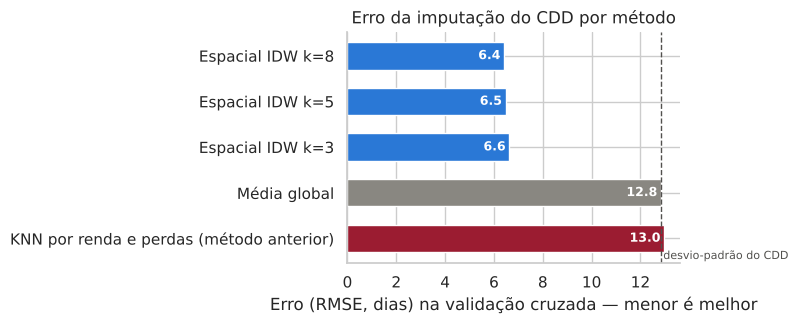

In [26]:
# ── 25.2 Imputação ESPACIAL do CDD (vizinhos geográficos, inverso da distância²) ─────────────────────
# Chuva é um fenômeno espacial: o CDD de um município sem pixel de satélite se parece com o dos municípios VIZINHOS,
# não com o dos municípios de renda e perdas parecidas. O método anterior (KNN em renda e perdas) é comparado por
# validação cruzada (10 partes) nos municípios que TÊM CDD medido.
ARQ_COORD = 'municipios_br_coordenadas.csv'   # código IBGE, latitude e longitude (sede do município), SP
URL_COORD = 'https://raw.githubusercontent.com/kelvins/municipios-brasileiros/main/csv/municipios.csv'
if not os.path.exists(ARQ_COORD):
    _m = pd.read_csv(URL_COORD)
    _m[_m['codigo_uf'] == 35][['codigo_ibge', 'nome', 'latitude', 'longitude']].to_csv(ARQ_COORD, index=False)
coord = pd.read_csv(ARQ_COORD, dtype={'codigo_ibge': str})
coord['chave6'] = coord['codigo_ibge'].str[:6]
assert len(coord) == 645 and coord['chave6'].is_unique
assert coord['latitude'].between(-25.5, -19.5).all() and coord['longitude'].between(-53.5, -44.0).all(), 'coordenadas fora de SP'

df_final['lat'] = df_final['chave6'].map(coord.set_index('chave6')['latitude']).astype(float)
df_final['lon'] = df_final['chave6'].map(coord.set_index('chave6')['longitude']).astype(float)
assert df_final[['lat', 'lon']].notna().all().all(), 'município sem coordenada'

# Doadores: TODOS os municípios com pixel de satélite (independe de terem dado no SNIS)
clima6 = df_clima.assign(chave6=df_clima['id'].astype(str).str.strip().str[:6]).drop_duplicates('chave6')
doad = clima6.merge(coord[['chave6', 'latitude', 'longitude']], on='chave6', how='inner')
assert len(doad) == len(clima6)
df_final['cdd_imputado'] = ~df_final['chave6'].isin(set(clima6['chave6']))
print(f"Municípios com CDD medido pelo satélite: {(~df_final['cdd_imputado']).sum()} | sem pixel (a imputar): {df_final['cdd_imputado'].sum()}")

R_TERRA = 6371.0
def idw_espacial(coord_tr, y_tr, coord_te, k=5, p=2):
    """Média ponderada pelo inverso da distância^p dos k municípios medidos mais próximos (haversine, km)."""
    bt = BallTree(np.radians(coord_tr), metric='haversine')
    dist, ind = bt.query(np.radians(coord_te), k=k)
    w = 1.0 / np.maximum(dist * R_TERRA, 1e-3) ** p
    return (w * y_tr[ind]).sum(1) / w.sum(1)

# Validação cruzada: compara os métodos nos municípios da base final com CDD medido
med = df_final[~df_final['cdd_imputado']].reset_index(drop=True)
y = med['dias_consecutivos'].to_numpy(float); Cmed = med[['lat', 'lon']].to_numpy(float)
Zrp = StandardScaler().fit_transform(med[['renda_per_capita', 'indice_perdas_distribuicao']])
metodos = ['Média global', 'KNN por renda e perdas (método anterior)', 'Espacial IDW k=3', 'Espacial IDW k=5', 'Espacial IDW k=8']
pred = {m: np.zeros(len(med)) for m in metodos}
for tr, te in KFold(10, shuffle=True, random_state=0).split(med):
    pred['Média global'][te] = y[tr].mean()
    nn = NearestNeighbors(n_neighbors=5).fit(Zrp[tr]); dist, ind = nn.kneighbors(Zrp[te]); w = 1 / np.maximum(dist, 1e-9)
    pred['KNN por renda e perdas (método anterior)'][te] = (w * y[tr][ind]).sum(1) / w.sum(1)
    for k in (3, 5, 8):
        pred[f'Espacial IDW k={k}'][te] = idw_espacial(Cmed[tr], y[tr], Cmed[te], k=k)
CV_CDD = pd.DataFrame({m: dict(RMSE=np.sqrt(np.mean((p - y) ** 2)), MAE=np.mean(np.abs(p - y)), r=np.corrcoef(p, y)[0, 1])
                       for m, p in pred.items()}).T
print(f'Validação cruzada (10 partes) nos {len(med)} municípios com CDD medido | desvio-padrão do CDD = {y.std():.1f} dias')
display(CV_CDD.round(3))
assert CV_CDD.loc['Espacial IDW k=5', 'RMSE'] < CV_CDD.loc['KNN por renda e perdas (método anterior)', 'RMSE'], 'a imputação espacial deveria vencer'

# Aplica aos municípios sem pixel (k=5, doadores = todos com pixel)
m_imp = df_final['cdd_imputado'].to_numpy()
df_final.loc[m_imp, 'dias_consecutivos'] = idw_espacial(doad[['latitude', 'longitude']].to_numpy(float),
                                                        doad['dias_consecutivos'].to_numpy(float),
                                                        df_final.loc[m_imp, ['lat', 'lon']].to_numpy(float), k=5).round(1)
assert df_final['dias_consecutivos'].notna().all()
print(f"\nCDD imputado nos {m_imp.sum()} municípios: de {df_final.loc[m_imp, 'dias_consecutivos'].min():.1f} a "
      f"{df_final.loc[m_imp, 'dias_consecutivos'].max():.1f} dias (média {df_final.loc[m_imp, 'dias_consecutivos'].mean():.1f})")

# Figura: erro de cada método
fig, ax = plt.subplots(figsize=(8, 3.4))
cv = CV_CDD['RMSE'].sort_values(ascending=False)
cores = ['#2a78d6' if 'Espacial' in i else '#9b1c31' if 'anterior' in i else '#898781' for i in cv.index]
ax.barh(cv.index, cv.values, color=cores, height=0.6)
ax.axvline(y.std(), color='#52514e', ls='--', lw=1); ax.text(y.std() + 0.1, -0.45, 'desvio-padrão do CDD', fontsize=8, color='#52514e')
for i, v in enumerate(cv.values): ax.text(v - 0.15, i, f'{v:.1f}', va='center', ha='right', color='white', fontsize=9, fontweight='bold')
ax.set_xlabel('Erro (RMSE, dias) na validação cruzada — menor é melhor'); ax.set_title('Erro da imputação do CDD por método')
for s in ('top', 'right'): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig('fig_cv_imputacao_cdd.png', dpi=200, bbox_inches='tight'); plt.show()


In [27]:
# ── 25.3 Verificação final da base ───────────────────────────────────────────────────────────────────
print("=== Verificação final da base ===")
print(f"Linhas em df_final: {len(df_final)} | IDs únicos: {df_final['id_municipio'].nunique()} | duplicatas: {len(df_final) - df_final['id_municipio'].nunique()}")
print("Valores ausentes nas variáveis de modelagem:")
print(df_final[['renda_per_capita', 'indice_perdas_distribuicao', 'dias_consecutivos']].isna().sum().to_string())

# O CDD imputado não deve distorcer a distribuição do CDD medido
media_original = clima6['dias_consecutivos'].mean(); dp_original = clima6['dias_consecutivos'].std(ddof=1)
media_final = df_final['dias_consecutivos'].mean();  dp_final = df_final['dias_consecutivos'].std(ddof=1)
print(f"\nCDD medido (satélite): média={media_original:.2f}, dp={dp_original:.2f}")
print(f"CDD final (medido + imputado): média={media_final:.2f}, dp={dp_final:.2f}")
print(f"Diferença relativa na média: {abs(media_final - media_original) / media_original * 100:.2f}% | no desvio padrão: {abs(dp_final - dp_original) / dp_original * 100:.2f}%")


=== Verificação final da base ===
Linhas em df_final: 633 | IDs únicos: 633 | duplicatas: 0
Valores ausentes nas variáveis de modelagem:
renda_per_capita              0
indice_perdas_distribuicao    0
dias_consecutivos             0

CDD medido (satélite): média=42.99, dp=12.80
CDD final (medido + imputado): média=42.49, dp=12.94
Diferença relativa na média: 1.16% | no desvio padrão: 1.12%


### Interpretação da imputação espacial

**Validação cruzada (10 partes, nos 587 municípios com CDD medido).** O erro (RMSE) do método anterior, KNN em renda e perdas, é de **13,0 dias**, igual ao de simplesmente usar a média global (12,8 dias, que é o próprio desvio padrão do CDD): a imputação anterior não trazia informação. A imputação espacial com k = 5 tem RMSE de **6,5 dias** (metade do erro), correlação de 0,86 com o valor medido e erro absoluto médio de 3,6 dias. Variar k entre 3 e 8 muda pouco o resultado (RMSE de 6,4 a 6,6), o que indica que a escolha de k = 5 não é crítica.

**Efeito na base.** Os 46 municípios receberam CDD de 15,5 a 51,0 dias (média 37,1), dentro do intervalo observado (14 a 85 dias). A distribuição do CDD mantém média (42,5 contra 43,0 dias) e desvio padrão (12,9 contra 12,8 dias) praticamente idênticos aos da base medida de 587 municípios (diferenças relativas de 1,2% e 1,1%).

**Limitação.** A imputação espacial é uma estimativa e herda a bimodalidade regional: os municípios sem pixel no litoral ou em áreas de transição podem ter erro maior do que a média da validação. A base final tem **633 municípios** e **zero valores ausentes** nas três variáveis de modelagem.

## 26. Normalização Z-Score Final (Base Completa)

Com o `df_final` completo (633 municípios), aplica-se a normalização Z-score definitiva nas três variáveis de modelagem. Esta é a versão que alimentará o algoritmo de clusterização K-Means. O gráfico comparativo confirma que a padronização elimina as diferenças de magnitude entre as escalas originais.

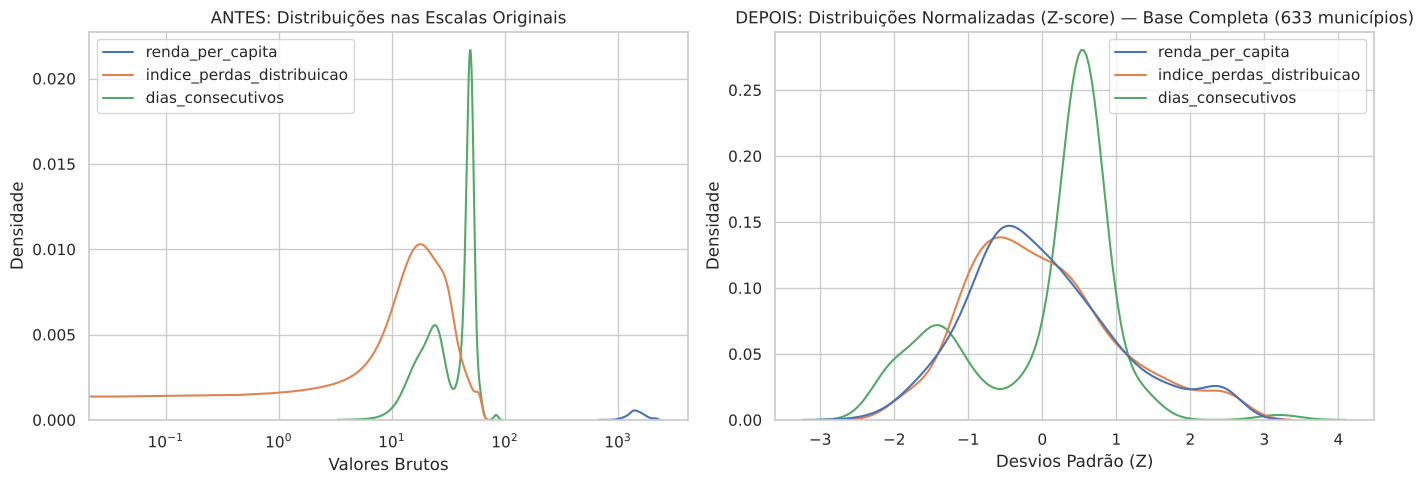

Estatísticas após normalização (deve ser ~0 de média e ~1 de desvio):


,renda_per_capita,indice_perdas_distribuicao,dias_consecutivos
count,633.0000,633.0000,633.0000
mean,0.0000,0.0000,0.0000
std,1.0008,1.0008,1.0008
min,-2.4128,-1.9028,-2.2027
25%,-0.6691,-0.7310,-0.8110
50%,-0.1459,-0.1142,0.4261
75%,0.5859,0.5792,0.5807
max,2.4370,2.5444,3.2868


In [28]:
cols_modelo = ['renda_per_capita', 'indice_perdas_distribuicao', 'dias_consecutivos']
df_bruto_final = df_final[cols_modelo].copy()

# Normalização Z-score para uso nos modelos
scaler_final = StandardScaler()
arr_norm = scaler_final.fit_transform(df_bruto_final)
df_zscore = pd.DataFrame(arr_norm, columns=cols_modelo, index=df_final.index)

# Adicionar ao df_final como colunas separadas (preservando os valores originais)
df_final['z_renda']  = df_zscore['renda_per_capita']
df_final['z_perdas'] = df_zscore['indice_perdas_distribuicao']
df_final['z_cdd']    = df_zscore['dias_consecutivos']

# Painel comparativo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(data=df_bruto_final, ax=axes[0])
axes[0].set_title('ANTES: Distribuições nas Escalas Originais')
axes[0].set_ylabel('Densidade')
axes[0].set_xlabel('Valores Brutos')
axes[0].set_xscale('log')

sns.kdeplot(data=df_zscore, ax=axes[1])
axes[1].set_title(f'DEPOIS: Distribuições Normalizadas (Z-score) — Base Completa ({len(df_final)} municípios)')
axes[1].set_ylabel('Densidade')
axes[1].set_xlabel('Desvios Padrão (Z)')

plt.tight_layout()
plt.show()

print("Estatísticas após normalização (deve ser ~0 de média e ~1 de desvio):")
display(df_zscore.describe().round(4))


### Interpretação da normalização final

A normalização Z-score definitiva é aplicada sobre a base completa de 633 municípios (após a imputação espacial do CDD).

As colunas `z_renda`, `z_perdas` e `z_cdd` são adicionadas ao `df_final` como variáveis de entrada para o algoritmo, preservando os valores originais para fins de interpretação dos resultados. As médias das colunas normalizadas são zero e os desvios padrão são 1,0008 (a diferença para 1 vem do desvio com divisor n, usado pelo `StandardScaler`), confirmando a corretude da transformação.

O `df_final` está agora pronto para a etapa de clusterização. O sumário das variáveis normalizadas que alimentarão o modelo é:
- **`z_renda`**: capacidade socioeconômica local (proxy da resiliência a crises de abastecimento)
- **`z_perdas`**: ineficiência operacional da rede de distribuição (suscetibilidade estrutural)
- **`z_cdd`**: exposição ao estresse hídrico climático (ameaça ambiental)

## 27. Sumário Final do Pré-Processamento

Esta célula consolida um relatório do estado final da base de dados, confirmando que o pipeline de tratamento está concluído e o `df_final` está pronto para a clusterização.

In [29]:
n_med, n_imp = int((~df_final['cdd_imputado']).sum()), int(df_final['cdd_imputado'].sum())
print("=" * 60)
print("  SUMÁRIO DO PRÉ-PROCESSAMENTO — df_final")
print("=" * 60)
print(f"  Municípios na base final:          {len(df_final)}")
print(f"  Variáveis de modelagem:             3  (renda, perdas, CDD)")
print(f"  Valores ausentes restantes:         {df_final[['renda_per_capita','indice_perdas_distribuicao','dias_consecutivos']].isna().sum().sum()}")
print()
print("  -- Cobertura por fonte --")
print(f"  SNIS (perdas):        {df_final['indice_perdas_distribuicao'].notna().sum()} municípios (excluídos: 2 sem SNIS e 10 com perdas = 0,00%)")
print(f"  IBGE (renda):         {df_final['renda_per_capita'].notna().sum()} municípios")
print(f"  MERGE/INPE (CDD):     {n_med} medidos + {n_imp} imputados (IDW espacial) = {df_final['dias_consecutivos'].notna().sum()} municípios")
print()
print("  -- Tratamentos aplicados --")
print("  [x] Remoção de nulos estruturais (4 perdas, 17 renda)")
print("  [x] Perdas = 0,00% tratadas como dado ausente (10 municípios, seção 4.1)")
print("  [x] Winsorização IQR: renda (24 outliers) e perdas (17 outliers)")
print(f"  [x] Imputação espacial IDW (k=5, inverso da distância²) do CDD: {n_imp} municípios sem pixel")
print("  [x] Normalização Z-score: z_renda, z_perdas, z_cdd")
print()
print("  -- Próxima etapa --")
print("  Clusterização K-Means (k=4), validação externa (PNSB 2017, ISH-U) e testes de robustez")
print("=" * 60)
print()
display("Primeiras linhas do df_final pronto para clusterização:",
        df_final[['municipio','renda_per_capita','indice_perdas_distribuicao','dias_consecutivos',
                   'z_renda','z_perdas','z_cdd']].head(8).round(3))


  SUMÁRIO DO PRÉ-PROCESSAMENTO — df_final
  Municípios na base final:          633
  Variáveis de modelagem:             3  (renda, perdas, CDD)
  Valores ausentes restantes:         0

  -- Cobertura por fonte --
  SNIS (perdas):        633 municípios (excluídos: 2 sem SNIS e 10 com perdas = 0,00%)
  IBGE (renda):         633 municípios
  MERGE/INPE (CDD):     587 medidos + 46 imputados (IDW espacial) = 633 municípios

  -- Tratamentos aplicados --
  [x] Remoção de nulos estruturais (4 perdas, 17 renda)
  [x] Perdas = 0,00% tratadas como dado ausente (10 municípios, seção 4.1)
  [x] Winsorização IQR: renda (24 outliers) e perdas (17 outliers)
  [x] Imputação espacial IDW (k=5, inverso da distância²) do CDD: 46 municípios sem pixel
  [x] Normalização Z-score: z_renda, z_perdas, z_cdd

  -- Próxima etapa --
  Clusterização K-Means (k=4), validação externa (PNSB 2017, ISH-U) e testes de robustez



'Primeiras linhas do df_final pronto para clusterização:'

,municipio,renda_per_capita,indice_perdas_distribuicao,dias_consecutivos,z_renda,z_perdas,z_cdd
0,Adamantina,1868.26,23.850,50.0,1.293,-0.130,0.581
1,Adolfo,1514.80,9.720,27.0,-0.044,-1.181,-1.198
2,Aguaí,1321.67,59.795,47.0,-0.774,2.544,0.349
3,Águas da Prata,1684.99,35.380,47.0,0.600,0.728,0.349
4,Águas de Lindóia,1742.52,40.030,43.6,0.818,1.074,0.086
5,Águas de Santa Bárbara,1946.69,37.340,47.0,1.590,0.874,0.349
6,Águas de São Pedro,2170.64,18.950,48.1,2.437,-0.494,0.434
7,Agudos,1590.76,33.910,47.0,0.244,0.619,0.349


### Interpretação do sumário final

O pipeline de pré-processamento está concluído. O `df_final` contém **633 municípios** do Estado de São Paulo com perdas de água válidas, com **zero valores ausentes** nas três variáveis de modelagem. Os outros 12 municípios da malha do IBGE ficam fora do estudo: 2 não constam na base de perdas de água e 10 reportaram perdas de 0,00%, que foram tratadas como dado ausente.

A migração da fonte climática, de estações INMET/BigQuery (38 municípios, cobertura de 5,9%) para o produto satelital MERGE/INPE com cruzamento espacial (587 dos 633 municípios da base final, cobertura de 92,7%), representa um salto qualitativo expressivo: o modelo passa a contar com dados climáticos observados para a quase totalidade do território, recorrendo à imputação espacial apenas para os 46 municípios sem pixel de precipitação dentro de seus limites.

As variáveis normalizadas `z_renda`, `z_perdas` e `z_cdd` estão prontas para alimentar o algoritmo **K-Means** (com inicialização K-Means++). A escolha do número de clusters `k` será guiada pelo Método do Cotovelo (SSE) e validada pelo Silhouette Score e por outros critérios.

---
## 28. Clusterização — K-Means

Aplicamos o algoritmo K-Means com inicialização **K-Means++** (50 inicializações, semente 42) às variáveis normalizadas `z_renda`, `z_perdas` e `z_cdd` dos 633 municípios. Esta seção define a solução final com **4 clusters**, nomeia os perfis, avalia a qualidade, apresenta as figuras e exporta o resultado.

**Paleta única.** Todas as figuras de cluster usam as mesmas quatro cores, atribuídas ao **perfil** (em ordem crescente de vulnerabilidade) e não ao número que o K-Means dá ao cluster: C1 azul (baixa vulnerabilidade), C2 verde (moderada, baixa renda), C3 amarelo (moderada, alta exposição à seca) e C4 vinho (alta, perdas elevadas). Municípios sem perdas válidas aparecem em cinza hachurado. A paleta foi verificada para daltonismo (diferença de cor entre todos os pares acima de 9 na escala OKLab, para protanopia e deuteranopia).

### 28.1 Escolha do número de clusters

Matriz de entrada: 633 municípios x 3 variáveis


,inercia_SSE,silhouette,calinski_harabasz,davies_bouldin
k,,,,
2,1340.447,0.364,262.932,1.223
3,920.407,0.376,334.913,1.067
4,725.596,0.390,339.064,1.004
5,628.005,0.328,317.746,1.017
6,562.434,0.311,298.000,1.042
7,502.684,0.307,289.809,1.081
8,452.940,0.308,285.061,1.056
9,415.238,0.305,278.732,1.034
10,380.411,0.312,276.333,0.989


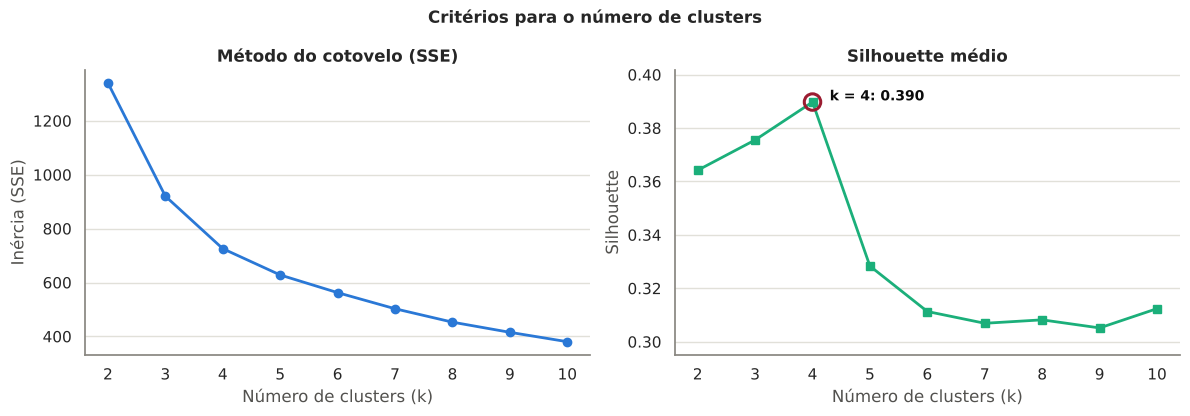

Silhouette por k: {2: 0.364, 3: 0.376, 4: 0.39, 5: 0.328, 6: 0.311, 7: 0.307, 8: 0.308, 9: 0.305, 10: 0.312}


In [30]:
# ── 28.1 Matriz de entrada, paleta única e escolha de k ──────────────────────────────────────────────
base3 = ['renda_per_capita', 'indice_perdas_distribuicao', 'dias_consecutivos']
X = df_final[['z_renda', 'z_perdas', 'z_cdd']].to_numpy()
SEED, N_INIT = 42, 50
print(f'Matriz de entrada: {X.shape[0]} municípios x {X.shape[1]} variáveis')

# PALETA ÚNICA DOS PERFIS: usada em TODAS as figuras de cluster (boxplots, 3D, mapa, heatmap, silhouette).
# A cor segue o perfil (ordem crescente do índice de vulnerabilidade), nunca o número do cluster no K-Means.
# Cores da paleta de referência, validadas para daltonismo (protan/deutan, ΔE ≥ 9 entre todos os pares; ver nota na seção 28.5).
COR_PERFIL = ['#2a78d6', '#1baf7a', '#eda100', '#9b1c31']     # C1 (menor vulnerabilidade) ... C4 (maior)
COR_SEM_DADO = '#c3c2b7'                                       # municípios sem índice de perdas informado
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e1e0d9'
plt.rcParams.update({'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#898781',
                     'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.labelcolor': INK2, 'font.size': 10})

# Critérios para a escolha de k (k = 2 a 10)
linhas, modelos = [], {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, init='k-means++', n_init=N_INIT, random_state=SEED, max_iter=500).fit(X)
    modelos[k] = km
    linhas.append(dict(k=k, inercia_SSE=km.inertia_, silhouette=silhouette_score(X, km.labels_),
                       calinski_harabasz=calinski_harabasz_score(X, km.labels_), davies_bouldin=davies_bouldin_score(X, km.labels_)))
AVAL = pd.DataFrame(linhas).set_index('k')
display(AVAL.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(AVAL.index, AVAL['inercia_SSE'], 'o-', color='#2a78d6', lw=2, ms=6)
axes[0].set_title('Método do cotovelo (SSE)'); axes[0].set_xlabel('Número de clusters (k)'); axes[0].set_ylabel('Inércia (SSE)')
axes[1].plot(AVAL.index, AVAL['silhouette'], 's-', color='#1baf7a', lw=2, ms=6)
axes[1].set_title('Silhouette médio'); axes[1].set_xlabel('Número de clusters (k)'); axes[1].set_ylabel('Silhouette')
K_FINAL = 4
axes[1].scatter([K_FINAL], [AVAL.loc[K_FINAL, 'silhouette']], s=140, facecolors='none', edgecolors='#9b1c31', linewidths=2.2, zorder=5)
axes[1].set_ylim(AVAL['silhouette'].min() - 0.01, AVAL['silhouette'].max() + 0.012)
axes[1].text(K_FINAL + 0.3, AVAL.loc[K_FINAL, 'silhouette'] + 0.002, f'k = {K_FINAL}: {AVAL.loc[K_FINAL, "silhouette"]:.3f}', fontsize=10, color=INK, fontweight='bold', va='center')
for ax in axes: ax.set_xticks(list(AVAL.index)); ax.grid(axis='y', color=GRID); ax.set_axisbelow(True)
plt.suptitle('Critérios para o número de clusters', fontweight='bold'); plt.tight_layout()
plt.savefig('fig_selecao_k.png', dpi=200, bbox_inches='tight'); plt.show()
print('Silhouette por k:', {k: round(v, 3) for k, v in AVAL['silhouette'].items()})


**Leitura.** O Silhouette médio é máximo em **k = 4 (0,390)**, acima de k = 3 (0,376) e k = 2 (0,364), e cai de forma clara em k = 5 (0,328) e a partir daí fica em torno de 0,31. O Calinski-Harabasz também é máximo em k = 4 (339,1). O cotovelo da inércia é suave, sem um ponto de quebra nítido, o que é comum em dados contínuos sem grupos bem separados, e por isso o Silhouette e o Calinski-Harabasz pesam mais na decisão. O Davies-Bouldin (menor é melhor) é um pouco menor em k = 10 (0,989) do que em k = 4 (1,004), mas com 10 grupos os perfis ficariam pequenos e difíceis de interpretar. Adota-se **k = 4**.

Um ponto de honestidade metodológica: o Silhouette de 0,39 indica estrutura **moderada**, não grupos nitidamente separados. Os clusters são uma partição útil de um contínuo, e as fronteiras entre eles são graduais (seção 28.3).

### 28.2 Modelo final (k = 4), rotulação e perfis

In [31]:
# ── 28.2 Modelo final (k = 4): rotulação por índice de vulnerabilidade e renumeração dos clusters ────
km_final = modelos[K_FINAL]
colunas_z = ['z_renda', 'z_perdas', 'z_cdd']
sinais = np.array([-1, +1, +1])          # renda: maior renda = menor vulnerabilidade | perdas e CDD: maior = mais vulnerabilidade

# Índice de vulnerabilidade (IV) de cada cluster = soma das contribuições orientadas do centróide
contrib_bruto = pd.DataFrame(km_final.cluster_centers_ * sinais, columns=colunas_z)
contrib_bruto['IV'] = contrib_bruto[colunas_z].sum(axis=1)

# Renumera os clusters por IV crescente: C1 = menor vulnerabilidade ... C4 = maior. A numeração do K-Means é arbitrária
# (muda com a semente); a ordem por IV é estável e é a que aparece em todas as figuras e tabelas.
ordem = contrib_bruto['IV'].sort_values().index.tolist()
antigo_para_novo = {antigo: novo for novo, antigo in enumerate(ordem, start=1)}
df_final['cluster'] = pd.Series(km_final.labels_, index=df_final.index).map(antigo_para_novo)
centroides = km_final.cluster_centers_[ordem]                     # linha i = cluster i+1
contrib = pd.DataFrame(centroides * sinais, columns=colunas_z, index=range(1, K_FINAL + 1))
contrib['IV'] = contrib[colunas_z].sum(axis=1)

# Rótulos: menor IV = Baixa | maior IV = Alta | intermediários = Moderada (com o fator de pressão dominante)
nomes_fator = {'z_renda': 'baixa renda', 'z_perdas': 'perdas elevadas', 'z_cdd': 'alta exposição à seca'}
fator = contrib[colunas_z].idxmax(axis=1).map(nomes_fator)
rotulo = {1: 'Baixa', K_FINAL: 'Alta', **{c: 'Moderada' for c in range(2, K_FINAL)}}
PERFIL = {c: ('Baixa Vulnerabilidade' if rotulo[c] == 'Baixa' else f'{rotulo[c]} ({fator[c]})') for c in range(1, K_FINAL + 1)}
PERFIL_CURTO = {1: 'Baixa', **{c: f'{rotulo[c]} · {fator[c]}'.replace('alta exposição à seca', 'seca') for c in range(2, K_FINAL + 1)}}
COR = {c: COR_PERFIL[c - 1] for c in range(1, K_FINAL + 1)}
df_final['perfil_vulnerabilidade'] = df_final['cluster'].map(rotulo).map(lambda r: f'{r} Vulnerabilidade')
df_final['perfil_detalhado'] = df_final['cluster'].map(PERFIL)
assert df_final['perfil_detalhado'].notna().all() and df_final['perfil_detalhado'].nunique() == K_FINAL, 'rótulos duplicados ou ausentes'
df_final['IV'] = (df_final[colunas_z].to_numpy() * sinais).sum(axis=1)

print(f'K-Means k={K_FINAL} | inércia {km_final.inertia_:.1f} | Silhouette {silhouette_score(X, df_final["cluster"]):.4f}\n')
perfil = df_final.groupby('cluster').agg(municipios=('cluster', 'size'), renda_media=('renda_per_capita', 'mean'),
                                         perdas_media=('indice_perdas_distribuicao', 'mean'), cdd_medio=('dias_consecutivos', 'mean'),
                                         z_renda=('z_renda', 'mean'), z_perdas=('z_perdas', 'mean'), z_cdd=('z_cdd', 'mean'), IV=('IV', 'mean'))
perfil['pct'] = 100 * perfil['municipios'] / len(df_final)
perfil['perfil'] = perfil.index.map(PERFIL)
display(perfil.round(2))
print('Contribuições orientadas dos centróides (positivo = aumenta a vulnerabilidade):')
display(contrib.round(3))


K-Means k=4 | inércia 725.6 | Silhouette 0.3897



,municipios,renda_media,perdas_media,cdd_medio,z_renda,z_perdas,z_cdd,IV,pct,perfil
cluster,,,,,,,,,,
1,117,1929.59,28.65,42.25,1.53,0.23,-0.02,-1.32,18.48,Baixa Vulnerabilidade
2,136,1341.26,26.78,22.94,-0.70,0.09,-1.51,-0.72,21.48,Moderada (baixa renda)
3,278,1446.30,16.19,50.23,-0.30,-0.70,0.60,0.20,43.92,Moderada (alta exposição à seca)
4,102,1528.92,46.15,47.74,0.01,1.53,0.41,1.93,16.11,Alta (perdas elevadas)


Contribuições orientadas dos centróides (positivo = aumenta a vulnerabilidade):


,z_renda,z_perdas,z_cdd,IV
1,-1.525,0.228,-0.018,-1.316
2,0.700,0.088,-1.512,-0.723
3,0.303,-0.700,0.598,0.201
4,-0.010,1.529,0.406,1.925


Os clusters são rotulados por uma **regra explícita e reprodutível**, aplicada aos centróides em z-score. Cada dimensão é orientada para que valores positivos signifiquem maior vulnerabilidade, e o **índice de vulnerabilidade** do cluster é a soma das três contribuições:

$$IV = (-z_{renda}) + z_{perdas} + z_{cdd}$$

- **Baixa vulnerabilidade:** o cluster com o menor IV. **Alta vulnerabilidade:** o cluster com o maior IV. **Moderada:** os dois intermediários, distinguidos pelo **fator de pressão dominante** (a dimensão com maior contribuição positiva).
- Os clusters são **renumerados por IV crescente** (C1 a C4), de modo que a numeração e as cores não mudam se o modelo for retreinado com outra semente.

| Cluster | Municípios | Renda média | Perdas médias | CDD médio | IV | Perfil | Leitura |
|---|---|---|---|---|---|---|---|
| C1 | 117 (18,5%) | R$ 1.930 | 28,7% | 42 dias | −1,32 | **Baixa** | Maior renda do estado (+1,53 desvio); perdas e CDD na média. A renda alta compensa o resto. |
| C2 | 136 (21,5%) | R$ 1.341 | 26,8% | 23 dias | −0,72 | **Moderada** (baixa renda) | Menor renda (−0,70), perdas na média, mas a **menor exposição à seca** (CDD −1,51 desvio): sul e litoral. |
| C3 | 278 (43,9%) | R$ 1.446 | 16,2% | 50 dias | +0,20 | **Moderada** (alta exposição à seca) | Rede mais eficiente (perdas −0,70 desvio), mas CDD alto (+0,60) e renda levemente abaixo da média. Interior norte e oeste. |
| C4 | 102 (16,1%) | R$ 1.529 | 46,1% | 48 dias | +1,93 | **Alta** (perdas elevadas) | Perdas muito elevadas (+1,53 desvio) combinadas com seca acima da média e renda mediana. |

O IV pesa as três dimensões igualmente, o que é uma escolha metodológica. Os dois clusters moderados têm origens de vulnerabilidade distintas (renda no C2, clima no C3), e por isso o fator dominante é mantido na coluna `perfil_detalhado`.

### 28.3 Qualidade da solução e estabilidade

,silhouette_medio,silhouette_min,municipios_com_sil_negativo,perfil
cluster,,,,
1,0.205,-0.126,20,Baixa Vulnerabilidade
2,0.409,-0.079,3,Moderada (baixa renda)
3,0.499,0.075,0,Moderada (alta exposição à seca)
4,0.278,-0.063,7,Alta (perdas elevadas)


Silhouette global: 0.390 | Calinski-Harabasz: 339.1 | Davies-Bouldin: 1.004 | municípios com silhouette < 0: 30 (4.7%)


Estabilidade — outras sementes: ARI médio 0.978 (mín. 0.957) | bootstrap: ARI médio 0.890 (percentil 5: 0.802)


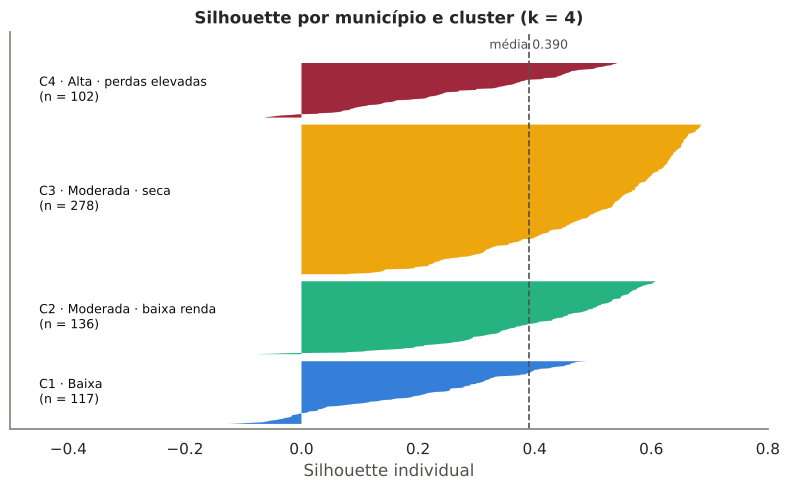

In [32]:
# ── 28.3 Qualidade da solução: Silhouette por cluster e estabilidade ─────────────────────────────────
sil_i = silhouette_samples(X, df_final['cluster'])
df_final['silhouette_i'] = sil_i
sil_cluster = df_final.groupby('cluster')['silhouette_i'].agg(['mean', 'min', lambda s: (s < 0).sum()])
sil_cluster.columns = ['silhouette_medio', 'silhouette_min', 'municipios_com_sil_negativo']
sil_cluster['perfil'] = sil_cluster.index.map(PERFIL)
display(sil_cluster.round(3))
print(f'Silhouette global: {sil_i.mean():.3f} | Calinski-Harabasz: {calinski_harabasz_score(X, df_final["cluster"]):.1f} | '
      f'Davies-Bouldin: {davies_bouldin_score(X, df_final["cluster"]):.3f} | municípios com silhouette < 0: {(sil_i < 0).sum()} ({100 * (sil_i < 0).mean():.1f}%)')

# Estabilidade (a) a outras sementes e (b) a reamostragem bootstrap: ARI contra a solução final (1 = idêntica)
rotulos_ref = df_final['cluster'].to_numpy()
ari_semente = [adjusted_rand_score(rotulos_ref, KMeans(K_FINAL, init='k-means++', n_init=10, random_state=s).fit_predict(X)) for s in range(100, 120)]
rng_b = np.random.default_rng(7)
ari_boot = []
for b in range(100):
    idx = rng_b.integers(0, len(X), len(X))
    kmb = KMeans(K_FINAL, init='k-means++', n_init=10, random_state=b).fit(X[idx])
    ari_boot.append(adjusted_rand_score(rotulos_ref, kmb.predict(X)))
ESTAB = dict(semente_media=np.mean(ari_semente), semente_min=np.min(ari_semente), boot_media=np.mean(ari_boot), boot_p5=np.percentile(ari_boot, 5))
print(f"Estabilidade — outras sementes: ARI médio {ESTAB['semente_media']:.3f} (mín. {ESTAB['semente_min']:.3f}) | "
      f"bootstrap: ARI médio {ESTAB['boot_media']:.3f} (percentil 5: {ESTAB['boot_p5']:.3f})")

# Figura: silhouette individual por cluster (faca) — cores dos perfis
fig, ax = plt.subplots(figsize=(8, 5))
y0 = 0
for c in range(1, K_FINAL + 1):
    v = np.sort(df_final.loc[df_final['cluster'] == c, 'silhouette_i'].to_numpy())
    ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=COR[c], edgecolor='none', alpha=0.95)
    ax.text(-0.45, y0 + len(v) / 2, f'C{c} · {PERFIL_CURTO[c]}\n(n = {len(v)})', va='center', fontsize=9, color=INK)
    y0 += len(v) + 12
ax.axvline(sil_i.mean(), color=INK2, ls='--', lw=1.2); ax.text(sil_i.mean(), y0 + 8, f'média {sil_i.mean():.3f}', fontsize=9, color=INK2, ha='center', va='bottom')
ax.set_xlim(-0.5, 0.8); ax.set_ylim(-10, y0 + 45); ax.set_yticks([]); ax.set_xlabel('Silhouette individual'); ax.set_title(f'Silhouette por município e cluster (k = {K_FINAL})')
plt.tight_layout(); plt.savefig('fig_silhouette_clusters.png', dpi=200, bbox_inches='tight'); plt.show()


**Leitura.** O Silhouette global é **0,390**, o Calinski-Harabasz é 339,1 e o Davies-Bouldin é 1,004. Por cluster, a coesão é boa no C3 (0,499, nenhum município com valor negativo) e no C2 (0,409), e mais fraca no C4 (0,278) e no C1 (0,205). Ao todo, 30 municípios (4,7%) têm Silhouette negativo, ou seja, estão mais próximos de outro cluster do que do seu; 20 deles são do C1. O C1 (baixa vulnerabilidade) se sobrepõe ao C4 e ao C3 porque a renda alta convive com perdas e CDD intermediários.

**Estabilidade.** Com 20 sementes diferentes, a solução é praticamente a mesma (ARI médio 0,978; mínimo 0,957). Com 100 reamostragens bootstrap, o ARI médio é 0,890 (percentil 5: 0,802): os grupos se mantêm quando cerca de 37% dos municípios ficam de fora de cada amostra e outros se repetem. A solução é estável, com fronteiras graduais.

### 28.4 Municípios representativos de cada cluster

In [33]:
# ── 28.4 Municípios mais representativos (mais próximos ao centróide de cada cluster) ────────────────
REPR = {}
for c in range(1, K_FINAL + 1):
    m = (df_final['cluster'] == c).to_numpy()
    d = np.linalg.norm(X[m] - centroides[c - 1], axis=1)
    idx = np.argsort(d)[:5]
    REPR[c] = df_final.loc[m, 'municipio'].to_numpy()[idx].tolist()
    print(f'C{c} — {PERFIL[c]} ({m.sum()} municípios): {", ".join(REPR[c])}')
    print(f'     renda R$ {df_final.loc[m, "renda_per_capita"].mean():,.0f} | perdas {df_final.loc[m, "indice_perdas_distribuicao"].mean():.1f}% | '
          f'CDD {df_final.loc[m, "dias_consecutivos"].mean():.0f} dias\n'.replace(',', '.'))


C1 — Baixa Vulnerabilidade (117 municípios): Nova Odessa, Tremembé, Louveira, Cerquilho, São João da Boa Vista
     renda R$ 1.930 | perdas 28.7% | CDD 42 dias

C2 — Moderada (baixa renda) (136 municípios): Alambari, Torre de Pedra, Itatinga, Monte Mor, Pratânia
     renda R$ 1.341 | perdas 26.8% | CDD 23 dias

C3 — Moderada (alta exposição à seca) (278 municípios): Zacarias, Vista Alegre do Alto, Santa Adélia, Presidente Epitácio, Macedônia
     renda R$ 1.446 | perdas 16.2% | CDD 50 dias

C4 — Alta (perdas elevadas) (102 municípios): Torrinha, Gavião Peixoto, Elisiário, Aparecida, Laranjal Paulista
     renda R$ 1.529 | perdas 46.1% | CDD 48 dias



**Leitura.** São os municípios mais próximos do centróide de cada cluster, ou seja, os que melhor representam o perfil: **C1**: Nova Odessa, Tremembé, Louveira, Cerquilho, São João da Boa Vista. **C2**: Alambari, Torre de Pedra, Itatinga, Monte Mor, Pratânia. **C3**: Zacarias, Vista Alegre do Alto, Santa Adélia, Presidente Epitácio, Macedônia. **C4**: Torrinha, Gavião Peixoto, Elisiário, Aparecida, Laranjal Paulista.

### 28.5 Figuras dos clusters

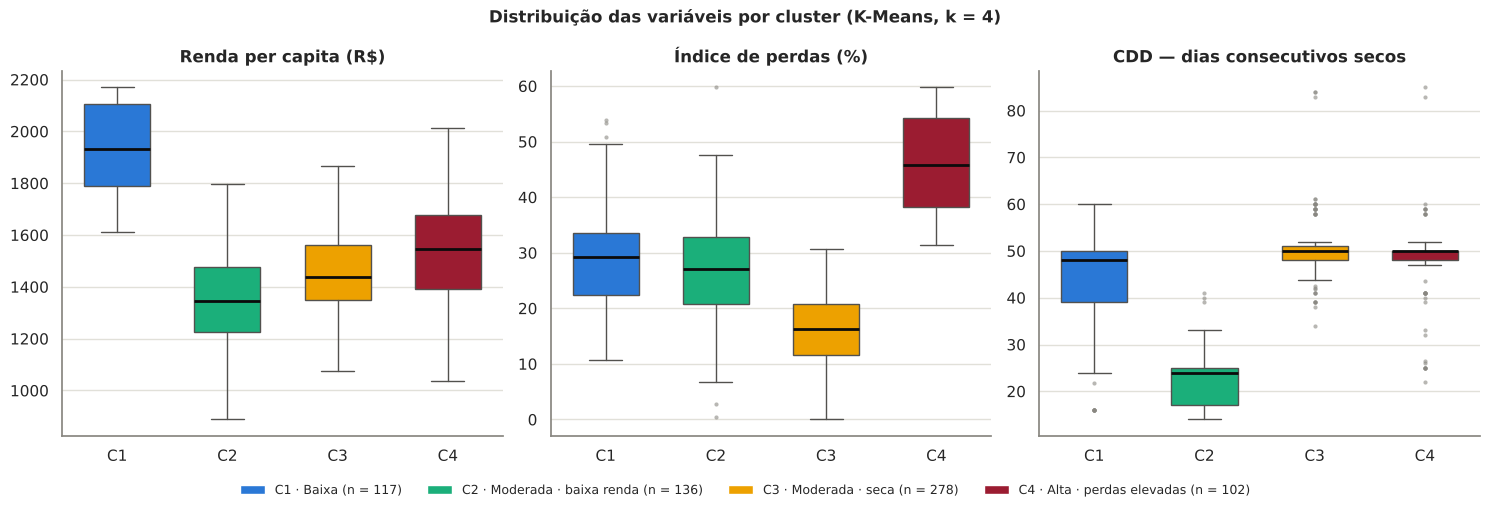

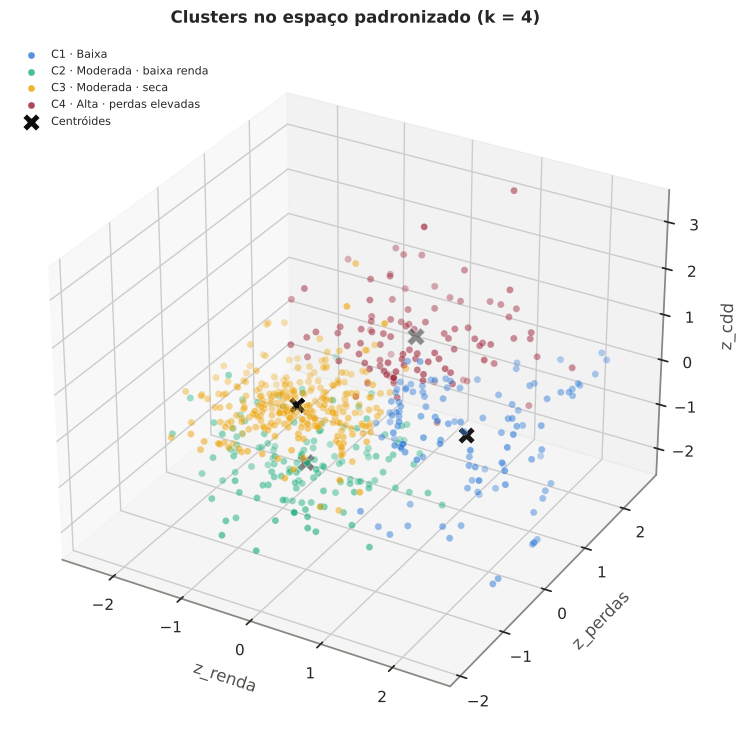

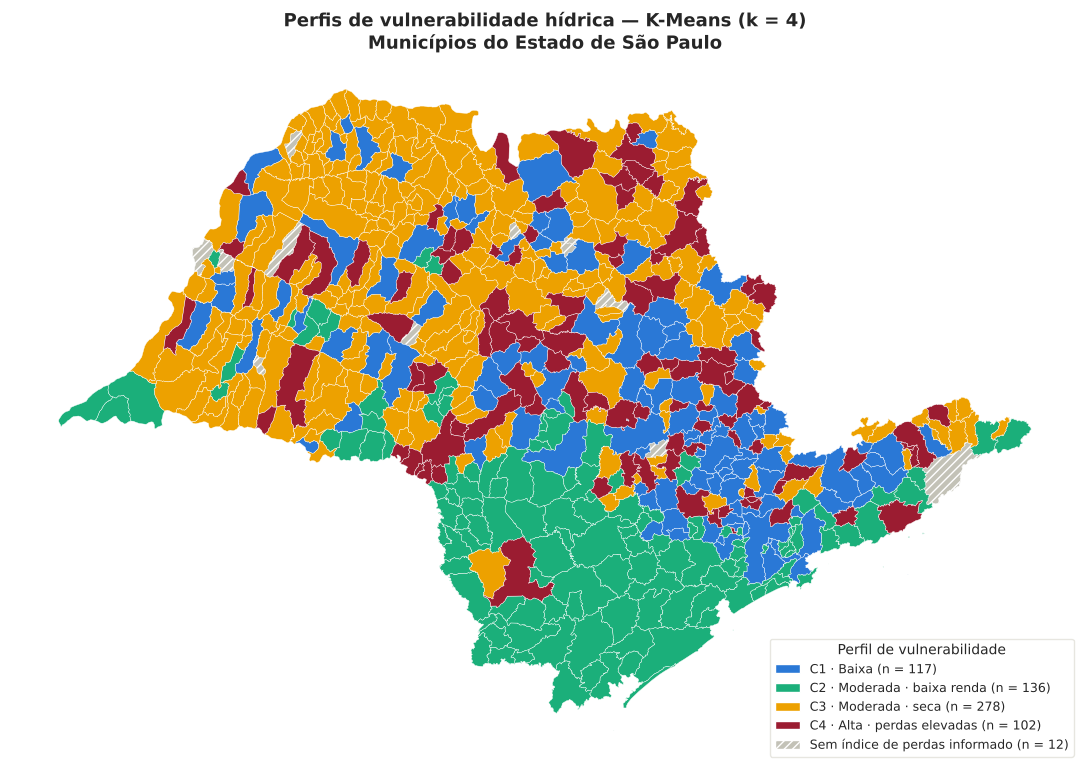

Municípios coloridos: 633 | sem perdas informadas (cinza hachurado): 12


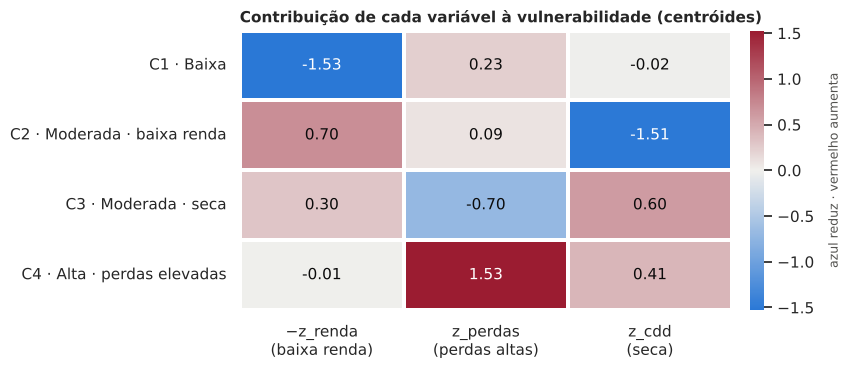

In [34]:
# ── 28.5 Figuras dos clusters (paleta única) ───────────────────────────────────────────────────────
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
legenda = [Patch(facecolor=COR[c], label=f'C{c} · {PERFIL_CURTO[c]} (n = {(df_final["cluster"] == c).sum()})') for c in range(1, K_FINAL + 1)]

# (a) Boxplots das variáveis originais por cluster
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (col, titulo) in zip(axes, [('renda_per_capita', 'Renda per capita (R$)'), ('indice_perdas_distribuicao', 'Índice de perdas (%)'),
                                    ('dias_consecutivos', 'CDD — dias consecutivos secos')]):
    dados = [df_final.loc[df_final['cluster'] == c, col] for c in range(1, K_FINAL + 1)]
    bp = ax.boxplot(dados, patch_artist=True, widths=0.6, medianprops=dict(color=INK, lw=2), whiskerprops=dict(color=INK2),
                    capprops=dict(color=INK2), flierprops=dict(marker='o', ms=3, markerfacecolor='#898781', markeredgecolor='none', alpha=0.6))
    for patch, c in zip(bp['boxes'], range(1, K_FINAL + 1)): patch.set_facecolor(COR[c]); patch.set_edgecolor(INK2)
    ax.set_xticklabels([f'C{c}' for c in range(1, K_FINAL + 1)]); ax.set_title(titulo); ax.grid(axis='y', color=GRID); ax.set_axisbelow(True)
fig.legend(handles=legenda, loc='lower center', ncol=4, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.06))
plt.suptitle(f'Distribuição das variáveis por cluster (K-Means, k = {K_FINAL})', fontweight='bold'); plt.tight_layout()
plt.savefig('fig_boxplots_clusters.png', dpi=200, bbox_inches='tight'); plt.show()

# (b) Dispersão 3D
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(10, 7.5)); ax3 = fig.add_subplot(111, projection='3d')
for c in range(1, K_FINAL + 1):
    m = df_final['cluster'] == c
    ax3.scatter(df_final.loc[m, 'z_renda'], df_final.loc[m, 'z_perdas'], df_final.loc[m, 'z_cdd'], c=COR[c], s=26, alpha=0.8,
                edgecolors='white', linewidths=0.3, label=f'C{c} · {PERFIL_CURTO[c]}')
ax3.scatter(centroides[:, 0], centroides[:, 1], centroides[:, 2], c=INK, marker='X', s=170, edgecolors='white', linewidths=1, label='Centróides', zorder=10)
ax3.grid(True); ax3.set_xlabel('z_renda', labelpad=8); ax3.set_ylabel('z_perdas', labelpad=8); ax3.set_zlabel('z_cdd', labelpad=8)
ax3.set_title(f'Clusters no espaço padronizado (k = {K_FINAL})', pad=12); ax3.legend(loc='upper left', fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig('fig_scatter3d_clusters.png', dpi=200, bbox_inches='tight'); plt.show()

# (c) Mapa dos clusters
mapa_sp['chave'] = mapa_sp['codarea'].astype(str).str[:6]
mapa_cl = mapa_sp.merge(df_final[['chave6', 'cluster']], left_on='chave', right_on='chave6', how='left')
fig, ax = plt.subplots(figsize=(11, 8.5))
sem = mapa_cl[mapa_cl['cluster'].isna()]
sem.plot(ax=ax, facecolor=COR_SEM_DADO, edgecolor='white', linewidth=0.3, hatch='////')
for c in range(1, K_FINAL + 1):
    mapa_cl[mapa_cl['cluster'] == c].plot(ax=ax, color=COR[c], edgecolor='white', linewidth=0.3)
leg = legenda + [Patch(facecolor=COR_SEM_DADO, hatch='////', edgecolor='white', label=f'Sem índice de perdas informado (n = {len(sem)})')]
ax.legend(handles=leg, loc='lower right', fontsize=9, title='Perfil de vulnerabilidade', title_fontsize=10, frameon=True, facecolor='white', edgecolor=GRID)
ax.set_title(f'Perfis de vulnerabilidade hídrica — K-Means (k = {K_FINAL})\nMunicípios do Estado de São Paulo', fontsize=13); ax.axis('off')
plt.tight_layout(); plt.savefig('fig_mapa_clusters.png', dpi=200, bbox_inches='tight'); plt.show()
print(f'Municípios coloridos: {mapa_cl["cluster"].notna().sum()} | sem perdas informadas (cinza hachurado): {len(sem)}')

# (d) Heatmap dos centróides: divergente azul-cinza-vermelho, positivo = maior vulnerabilidade
cmap_div = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#9b1c31'])
fig, ax = plt.subplots(figsize=(8.6, 3.8))
dados_h = contrib[colunas_z].rename(columns={'z_renda': '−z_renda\n(baixa renda)', 'z_perdas': 'z_perdas\n(perdas altas)', 'z_cdd': 'z_cdd\n(seca)'})
lim = np.abs(dados_h.to_numpy()).max()
sns.heatmap(dados_h, annot=True, fmt='.2f', cmap=cmap_div, center=0, vmin=-lim, vmax=lim, linewidths=1.5, linecolor='white', ax=ax,
            cbar_kws={'label': 'azul reduz · vermelho aumenta', 'pad': 0.03}, annot_kws={'fontsize': 11})
for t in ax.texts: t.set_color('white' if abs(float(t.get_text().replace('−', '-'))) >= 1.0 else INK)
ax.figure.axes[-1].yaxis.label.set_size(9); ax.figure.axes[-1].yaxis.labelpad = 10
ax.set_yticklabels([f'C{c} · {PERFIL_CURTO[c]}' for c in range(1, K_FINAL + 1)], rotation=0); ax.set_ylabel('')
ax.set_title('Contribuição de cada variável à vulnerabilidade (centróides)', loc='left', fontsize=11)
plt.tight_layout(); plt.savefig('fig_heatmap_centroides.png', dpi=200, bbox_inches='tight'); plt.show()


**Leitura.**

- **Boxplots:** a renda separa o C1 (mediana ~R$ 1.930) dos demais; o CDD separa o C2 (mediana ~24 dias) dos outros três (~48 a 50 dias); as perdas separam o C4 (mediana ~46%) e o C3 (~16%, o mais baixo). Cada cluster se destaca em uma dimensão diferente, o que torna os perfis interpretáveis.
- **Mapa:** o C2 (verde) forma um bloco contínuo no sul e no litoral, onde o CDD é baixo; o C3 (amarelo) predomina no noroeste e no interior norte; o C1 (azul) se concentra na região metropolitana, em Campinas e no Vale do Paraíba, onde a renda é mais alta; o C4 (vinho) aparece em manchas dispersas pelo interior (centro, nordeste, noroeste e sudoeste), refletindo a distribuição das perdas elevadas. Os 12 municípios hachurados não têm perdas válidas.
- **Heatmap dos centróides:** mostra que cada perfil tem uma "assinatura" dominante: renda alta no C1 (azul forte), CDD baixo no C2, perdas baixas e CDD alto no C3, perdas muito altas no C4.
- **Dispersão 3D:** os clusters se organizam como regiões vizinhas do espaço, sem fronteiras nítidas, coerente com o Silhouette moderado.

**Nota sobre a paleta.** As quatro cores foram escolhidas entre as da paleta de referência e validadas para visão de cores (protanopia, deuteranopia e tritanopia): a menor distância perceptual entre quaisquer duas cores é de 9,1 (protan/deutan, escala OKLab ×100) e de 22,9 para visão normal. As cores amarela e verde ficam abaixo de 3:1 de contraste contra fundo branco, e por isso todas as figuras trazem legenda e rótulo, e a informação nunca depende só da cor.

### 28.6 Municípios com perdas = 0,00%, efeito das correções e exportação

In [35]:
# ── 28.6 Os 10 municípios com perdas = 0,00%: classificação PROVISÓRIA (não entram no modelo) ───────
# Para cada um, usa a mediana de perdas das prefeituras com administração direta (a natureza jurídica de 9 dos 10) e
# aplica o modelo final. É só uma indicação: o que resolve é conferir o valor no SNIS.
med_pref = df_final.loc[df_final['natureza_juridica'].eq('Adm. Púb. Direta'), 'indice_perdas_distribuicao'].median()
zz = df_perdas_zero.copy(); zz['chave6'] = zz['id_municipio'].astype(str).str[:6]
zz['renda_per_capita'] = zz['chave6'].map(df_renda.assign(chave6=df_renda['id_municipio'].astype(str).str[:6]).set_index('chave6')['renda_per_capita'])
zz['lat'] = zz['chave6'].map(coord.set_index('chave6')['latitude']).astype(float); zz['lon'] = zz['chave6'].map(coord.set_index('chave6')['longitude']).astype(float)
zz['pixel'] = zz['chave6'].isin(set(clima6['chave6']))
zz['dias_consecutivos'] = np.where(zz['pixel'], zz['chave6'].map(clima6.set_index('chave6')['dias_consecutivos']),
                                   idw_espacial(doad[['latitude', 'longitude']].to_numpy(float), doad['dias_consecutivos'].to_numpy(float), zz[['lat', 'lon']].to_numpy(float)))
zz['indice_perdas_distribuicao'] = med_pref
Zz = scaler_final.transform(zz[base3])
zz['cluster_provisorio'] = km_final.predict(Zz); zz['cluster_provisorio'] = zz['cluster_provisorio'].map(antigo_para_novo)
zz['perfil_provisorio'] = zz['cluster_provisorio'].map(PERFIL)
display(zz[['municipio', 'natureza_juridica', 'renda_per_capita', 'dias_consecutivos', 'perfil_provisorio']].round(1))

# ── 28.7 Efeito das correções: versão anterior (643 municípios, zeros mantidos, CDD por KNN) x versão final ─────────
ant = pd.concat([df_final[['id_municipio', 'chave6', 'renda_per_capita', 'indice_perdas_distribuicao']],
                 zz[['id_municipio', 'chave6', 'renda_per_capita']].assign(indice_perdas_distribuicao=0.0)], ignore_index=True)
ant['dias_consecutivos'] = ant['chave6'].map(clima6.set_index('chave6')['dias_consecutivos'])           # NaN = sem pixel
sc_ant = StandardScaler(); Zant = pd.DataFrame(sc_ant.fit_transform(ant[base3]), columns=base3)
Zant_imp = pd.DataFrame(KNNImputer(n_neighbors=5, weights='distance').fit_transform(Zant), columns=base3)
Xant = StandardScaler().fit_transform(pd.DataFrame({'a': ant['renda_per_capita'], 'b': ant['indice_perdas_distribuicao'],
                                                    'c': (Zant_imp['dias_consecutivos'] * sc_ant.scale_[2] + sc_ant.mean_[2]).round(1)}))
km_ant = KMeans(K_FINAL, init='k-means++', n_init=N_INIT, random_state=SEED, max_iter=500).fit(Xant)
mant = ant['id_municipio'].isin(df_final['id_municipio']).to_numpy()
COMP = pd.DataFrame({'Versão anterior (643 municípios, perdas 0% mantidas, CDD por KNN)': dict(municipios=len(ant), silhouette=silhouette_score(Xant, km_ant.labels_)),
                     'Versão final (633 municípios, perdas 0% fora, CDD espacial)': dict(municipios=len(df_final), silhouette=silhouette_score(X, df_final['cluster']))}).T
display(COMP.round(3))
print(f"ARI entre as duas versões nos 633 municípios em comum: {adjusted_rand_score(km_ant.labels_[mant], df_final.set_index('id_municipio').loc[ant.loc[mant, 'id_municipio'], 'cluster'].to_numpy()):.3f}")

# ── 28.8 Exportação ────────────────────────────────────────────────────────────────────────────────────
saida = df_final[['id_municipio', 'municipio', 'natureza_juridica', 'renda_per_capita', 'indice_perdas_distribuicao', 'dias_consecutivos', 'cdd_imputado',
                  'z_renda', 'z_perdas', 'z_cdd', 'IV', 'cluster', 'perfil_vulnerabilidade', 'perfil_detalhado']].copy()
saida_zero = zz[['id_municipio', 'municipio', 'natureza_juridica', 'renda_per_capita', 'dias_consecutivos']].assign(
    indice_perdas_distribuicao=np.nan, cdd_imputado=~zz['pixel'], cluster=np.nan,
    perfil_vulnerabilidade='Sem índice de perdas informado', perfil_detalhado='Sem índice de perdas informado (provisório: ' + zz['perfil_provisorio'] + ')')
pd.concat([saida, saida_zero], ignore_index=True).sort_values('id_municipio').to_csv('resultado_clusters_final.csv', index=False)
print('Arquivo salvo: resultado_clusters_final.csv', (len(saida) + len(saida_zero), saida.shape[1]))


,municipio,natureza_juridica,renda_per_capita,dias_consecutivos,perfil_provisorio
0,Cunha,Administração pública direta,1243.8,15.0,Moderada (baixa renda)
1,Guaimbê,Administração pública direta,1236.0,50.0,Moderada (alta exposição à seca)
2,Indiana,Administração pública direta,1627.1,48.0,Moderada (alta exposição à seca)
3,Lavínia,Administração pública direta,1527.8,50.0,Moderada (alta exposição à seca)
4,Novais,Administração pública direta,1145.2,50.0,Moderada (alta exposição à seca)
5,Paulicéia,Administração pública direta,1196.6,50.0,Moderada (alta exposição à seca)
6,Rincão,Administração pública direta,1396.8,50.0,Moderada (alta exposição à seca)
7,Santa Fé do Sul,Autarquia,1938.2,50.0,Baixa Vulnerabilidade
8,Taiúva,Administração pública direta,1644.9,50.0,Moderada (alta exposição à seca)
9,Taquaral,Administração pública direta,1606.6,50.0,Moderada (alta exposição à seca)


,municipios,silhouette
"Versão anterior (643 municípios, perdas 0% mantidas, CDD por KNN)",643.0,0.389
"Versão final (633 municípios, perdas 0% fora, CDD espacial)",633.0,0.390


ARI entre as duas versões nos 633 municípios em comum: 0.902
Arquivo salvo: resultado_clusters_final.csv (643, 14)


**Leitura.**

- **Classificação provisória dos 10 municípios sem perdas informadas.** Atribuindo a eles a mediana de perdas das prefeituras diretas, 8 caem no C3 (moderada, alta exposição à seca), Cunha cai no C2 (CDD de 15 dias) e Santa Fé do Sul no C1. É só uma indicação: o resultado depende do valor atribuído, e o correto é conferir o dado no SNIS.
- **Efeito das correções.** O Silhouette praticamente não muda entre a versão anterior (643 municípios, zeros mantidos, CDD por KNN: 0,389) e a final (633 municípios, zeros fora, CDD espacial: 0,390). As correções **não melhoram a métrica; melhoram a validade dos dados**: o CDD imputado passa a ter erro de 6,5 dias em vez de 13,0, e deixam de existir municípios classificados com base em uma perda de 0%. O ARI de 0,90 entre as duas versões mostra que a estrutura geral é a mesma, e a maior parte da diferença vem dos municípios com CDD imputado.
- **Exportação.** O arquivo `resultado_clusters_final.csv` contém os 643 municípios (633 classificados e 10 marcados como "sem índice de perdas informado", com a classificação provisória na coluna de detalhe).

---
## 29. Validação externa dos clusters

Um agrupamento pode ter Silhouette moderado e ainda assim ser útil. A pergunta decisiva é se os clusters correspondem a diferenças **reais**, medidas por fontes que o modelo não usou. Esta seção compara os perfis com três fontes externas: a PNSB 2017 (IBGE), o ISH-U da ANA e o Censo 2022 (população). Nenhuma delas entra no agrupamento.

### 29.1 PNSB 2017: racionamento e interrupção do abastecimento

In [36]:
# ── 29.1 Validação EXTERNA com a PNSB 2017 (IBGE): racionamento e interrupção do abastecimento ───────
# Variáveis que NÃO entram no agrupamento. Se os perfis fazem sentido, os de maior vulnerabilidade devem relatar mais racionamento.
# Fonte: SIDRA/IBGE, tabelas 7487 (racionamento), 7484 (interrupção >= 6 h), 7468 (tipo de captação), 7465 (volume captado); ano 2017.
from sklearn.metrics import roc_auc_score
pn = pd.read_csv('pnsb2017_agua_sp.csv', dtype={'codigo_ibge': str}); pn['chave6'] = pn['codigo_ibge'].str[:6]
assert len(pn) == 645 and pn['chave6'].is_unique and set(pn['racionamento_2017'].unique()) <= {0, 1}
print(f"PNSB 2017 em SP: racionamento em {pn['racionamento_2017'].sum()} municípios, interrupção >= 6 h em {pn['interrupcao_2017'].sum()}, "
      f"captação superficial em {pn['captacao_superficial_2017'].sum()} (de 645)")
val = df_final.merge(pn.drop(columns='codigo_ibge'), on='chave6', how='left'); assert val['racionamento_2017'].notna().all() and len(val) == len(df_final)

rng = np.random.default_rng(1)
def _chi2_bin(r, d, k):
    """Qui-quadrado de Pearson (cluster x desfecho binário), vetorizado."""
    n_c = np.bincount(r, minlength=k).astype(float); pos = np.bincount(r, weights=d, minlength=k); tot = d.sum(); N = len(d)
    E1 = n_c * tot / N; E0 = n_c * (N - tot) / N
    return np.sum((pos - E1) ** 2 / E1) + np.sum(((n_c - pos) - E0) ** 2 / E0)
def p_perm(rotulos, desfecho, n=10000):
    """p-valor de permutação (robusto a frequências esperadas pequenas)."""
    r = np.asarray(rotulos, dtype=int) - 1; d = np.asarray(desfecho, dtype=float); k = r.max() + 1
    obs = _chi2_bin(r, d, k); sim = np.array([_chi2_bin(r, rng.permutation(d), k) for _ in range(n)])
    return (1 + np.sum(sim >= obs)) / (n + 1)

VALID = {}
for desf, nome in [('racionamento_2017', 'Racionamento'), ('interrupcao_2017', 'Interrupção >= 6 h')]:
    tb = val.groupby('cluster')[desf].agg(['sum', 'size']).rename(columns={'sum': 'municipios_com', 'size': 'municipios'})
    tb['taxa_%'] = 100 * tb['municipios_com'] / tb['municipios']; tb['perfil'] = tb.index.map(PERFIL)
    p = p_perm(val['cluster'], val[desf])
    auc = {'IV (índice de vulnerabilidade)': roc_auc_score(val[desf], val['IV'])}
    auc.update({v: roc_auc_score(val[desf], s) for v, s in [('−z_renda', -val['z_renda']), ('z_perdas', val['z_perdas']), ('z_cdd', val['z_cdd'])]})
    VALID[desf] = (tb, p, auc)
    print(f'\n{nome} (taxa geral {100 * val[desf].mean():.1f}%) | p de permutação = {p:.4f}')
    display(tb.round(2)); print('AUC (discriminar quem teve o evento):', {k: round(v, 3) for k, v in auc.items()})


PNSB 2017 em SP: racionamento em 25 municípios, interrupção >= 6 h em 88, captação superficial em 310 (de 645)



Racionamento (taxa geral 3.8%) | p de permutação = 0.0008


,municipios_com,municipios,taxa_%,perfil
cluster,,,,
1,2,117,1.71,Baixa Vulnerabilidade
2,0,136,0.00,Moderada (baixa renda)
3,12,278,4.32,Moderada (alta exposição à seca)
4,10,102,9.80,Alta (perdas elevadas)


AUC (discriminar quem teve o evento): {'IV (índice de vulnerabilidade)': 0.677, '−z_renda': 0.476, 'z_perdas': 0.602, 'z_cdd': 0.675}



Interrupção >= 6 h (taxa geral 13.9%) | p de permutação = 0.4210


,municipios_com,municipios,taxa_%,perfil
cluster,,,,
1,16,117,13.68,Baixa Vulnerabilidade
2,15,136,11.03,Moderada (baixa renda)
3,38,278,13.67,Moderada (alta exposição à seca)
4,19,102,18.63,Alta (perdas elevadas)


AUC (discriminar quem teve o evento): {'IV (índice de vulnerabilidade)': 0.585, '−z_renda': 0.494, 'z_perdas': 0.572, 'z_cdd': 0.526}


**Leitura.**

- **Racionamento (p = 0,0008).** A taxa é maior nos clusters de maior vulnerabilidade: **4,3% no C3** e **9,8% no C4** (10 dos 102 municípios, cerca de 2,6 vezes a taxa geral de 3,8%), contra 1,7% no C1 e 0% no C2 (2 e 0 municípios com racionamento). A diferença entre os clusters é estatisticamente significativa (teste de permutação com 10 mil repetições, mais robusto do que o qui-quadrado porque há poucos eventos). O índice de vulnerabilidade discrimina quem teve racionamento com AUC de 0,68, com o CDD (0,675) e as perdas (0,60) como principais contribuintes.
- **Interrupção de 6 horas ou mais (p = 0,42).** Não há associação: as taxas ficam entre 11% e 19%, e o C4 tem a maior (18,6%), mas sem significância. A interrupção, como medida pela PNSB, depende de eventos pontuais (rompimentos, falta de energia) pouco ligados ao perfil estrutural.

Os dados da PNSB são de 2017 e as variáveis do modelo são de 2022; a comparação é de perfil estrutural, não de causa e efeito. Racionamento também é um evento raro (25 municípios no estado), o que limita o poder do teste.

### 29.2 ISH-U (ANA): Índice de Segurança Hídrica Urbano

Distribuição do ISH-U (% dos municípios de cada cluster):


ISH,Baixa,Média,Alta,Máxima
C1 · Baixa,6.0,33.3,45.3,15.4
C2 · Moderada · baixa renda,8.1,27.9,39.7,24.3
C3 · Moderada · seca,0.4,16.5,56.5,26.6
C4 · Alta · perdas elevadas,3.9,39.2,48.0,8.8


Kruskal-Wallis (ISH-U ordinal x cluster): H = 39.79, p = 1.18e-08


,ISH-U médio (1-4),Manancial superficial (0-3),Vulnerab. do manancial (0-3)
C1 · Baixa,2.70,1.77,0.26
C2 · Moderada · baixa renda,2.80,1.94,0.26
C3 · Moderada · seca,3.09,0.56,0.10
C4 · Alta · perdas elevadas,2.62,1.27,0.17


Spearman do ISH-U com as variáveis do modelo: {'renda_per_capita': np.float64(-0.13), 'indice_perdas_distribuicao': np.float64(-0.31), 'dias_consecutivos': np.float64(0.136)}
(o ISH-U incorpora indicadores de perdas; por isso não é totalmente independente do modelo e é usado só para validar.)


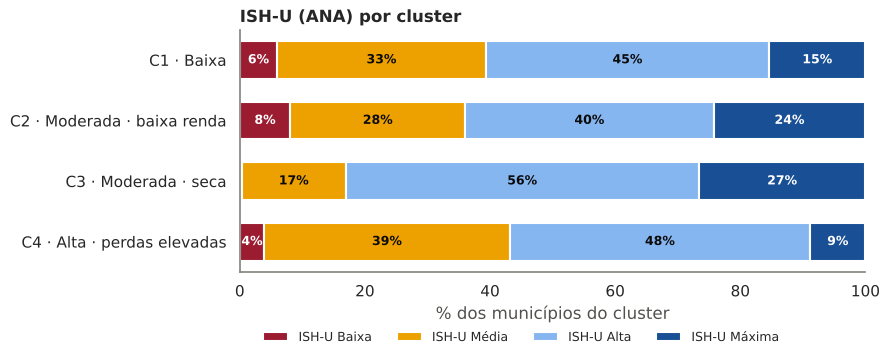

In [37]:
# ── 29.2 Validação EXTERNA com o ISH-U (ANA, Atlas de Abastecimento Urbano) ──────────────────────────
# ISH-U: Índice de Segurança Hídrica Urbano por município (Baixa < Média < Alta < Máxima segurança), com tipo e vulnerabilidade do manancial.
# Também NÃO entra no agrupamento. Se os perfis fazem sentido, deve haver associação com a segurança hídrica.
ish = pd.read_csv('ish_u_atlas_abastecimento.csv', encoding='utf-8-sig'); ish = ish[ish['SGUF'] == 'SP'].copy()
ish['chave6'] = ish['CDMUN'].astype(str).str[:6]; assert len(ish) == 645 and ish['chave6'].is_unique
ish['ish_ord'] = ish['ISH'].map({'Baixa': 1, 'Média': 2, 'Alta': 3, 'Máxima': 4})
ish['superficial_ord'] = ish['TPMAN'].map({'Exclusivamente Subterrânea': 0, 'Preponderantemente Subterrânea': 1, 'Preponderantemente Superficial': 2, 'Exclusivamente Superficial': 3})
ish['vulnerab_manancial'] = ish['CSMAN'].map({'Manancial Não Vulnerável': 0, 'Manancial com Baixa Vulnerabilidade': 1, 'Manancial com Média Vulnerabilidade': 2, 'Manancial com Alta Vulnerabilidade': 3})
vi = val.merge(ish[['chave6', 'ISH', 'ish_ord', 'superficial_ord', 'vulnerab_manancial']], on='chave6', how='left'); assert vi['ish_ord'].notna().all()

ct = pd.crosstab(vi['cluster'], vi['ISH'])[['Baixa', 'Média', 'Alta', 'Máxima']]
ct_pct = (100 * ct.div(ct.sum(axis=1), axis=0)).round(1); ct_pct.index = [f'C{c} · {PERFIL_CURTO[c]}' for c in ct_pct.index]
print('Distribuição do ISH-U (% dos municípios de cada cluster):'); display(ct_pct)
from scipy.stats import kruskal, spearmanr
H, p_kw = kruskal(*[g['ish_ord'].to_numpy() for _, g in vi.groupby('cluster')])
print(f'Kruskal-Wallis (ISH-U ordinal x cluster): H = {H:.2f}, p = {p_kw:.2e}')
medias_ish = vi.groupby('cluster')[['ish_ord', 'superficial_ord', 'vulnerab_manancial']].mean().round(2)
medias_ish.index = [f'C{c} · {PERFIL_CURTO[c]}' for c in medias_ish.index]
medias_ish.columns = ['ISH-U médio (1-4)', 'Manancial superficial (0-3)', 'Vulnerab. do manancial (0-3)']
display(medias_ish)
print('Spearman do ISH-U com as variáveis do modelo:', {v: round(spearmanr(vi['ish_ord'], vi[v])[0], 3) for v in base3})
print('(o ISH-U incorpora indicadores de perdas; por isso não é totalmente independente do modelo e é usado só para validar.)')

fig, ax = plt.subplots(figsize=(9, 3.8))
tons = ['#9b1c31', '#eda100', '#86b6ef', '#184f95']       # Baixa segurança (vermelho) -> Máxima (azul)
left = np.zeros(K_FINAL)
for cat, tom in zip(['Baixa', 'Média', 'Alta', 'Máxima'], tons):
    v = ct[cat].to_numpy() / ct.sum(axis=1).to_numpy() * 100
    ax.barh(range(K_FINAL), v, left=left, color=tom, edgecolor='white', linewidth=1.5, label=f'ISH-U {cat}', height=0.62)
    for i, (l, w) in enumerate(zip(left, v)):
        if w >= 3.5: ax.text(l + w / 2, i, f'{w:.0f}%', ha='center', va='center', color='white' if cat in ('Baixa', 'Máxima') else INK, fontsize=9, fontweight='bold')
    left += v
ax.set_yticks(range(K_FINAL)); ax.set_yticklabels([f'C{c} · {PERFIL_CURTO[c]}' for c in range(1, K_FINAL + 1)]); ax.invert_yaxis()
ax.set_xlabel('% dos municípios do cluster'); ax.set_xlim(0, 100); ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.45, -0.2), frameon=False, fontsize=9)
ax.set_title('ISH-U (ANA) por cluster', loc='left')
plt.tight_layout(); plt.savefig('fig_ish_por_cluster.png', dpi=200, bbox_inches='tight'); plt.show()


**Leitura.** O ISH-U difere entre os clusters (Kruskal-Wallis, p = 1,2 × 10⁻⁸), mas **não de forma monotônica com o índice de vulnerabilidade**:

- O **C4 (alta vulnerabilidade)** tem o menor ISH-U médio (2,62) e a menor fatia de municípios com segurança máxima (9%), o que é coerente com o rótulo.
- O **C3 (moderada, seca)** tem o maior ISH-U médio (3,09), com 83% dos municípios em Alta ou Máxima, e o menor uso de manancial superficial (0,56 em escala de 0 a 3, contra 1,3 a 1,9 nos demais). Esses municípios têm CDD alto, mas dependem sobretudo de manancial subterrâneo, menos sensível a períodos secos.
- O **C1 (baixa vulnerabilidade)** tem ISH-U médio de 2,70, abaixo do C3: renda alta não implica, por si só, maior segurança hídrica.

O ISH-U é, portanto, uma dimensão **complementar** ao modelo, e não uma réplica dele. Ele também incorpora indicadores de perdas (correlação de −0,31 com o índice de perdas do modelo), e por isso não é totalmente independente. O achado sugere que o tipo de manancial é uma dimensão importante que o modelo atual (renda, perdas, CDD) não captura; incluí-la como variável de entrada, no entanto, piora o Silhouette (seção 30.3).

### 29.3 População e densidade (Censo 2022)

In [38]:
# ── 29.3 Caracterização dos clusters com população e densidade (Censo 2022) — só descrição, não entra no modelo ─────
pop = pd.read_csv('populacao_censo2022_sp.csv', dtype={'codigo_ibge': str}); pop['chave6'] = pop['codigo_ibge'].str[:6]
cp = df_final.merge(pop[['chave6', 'populacao_residente_2022', 'densidade_hab_km2_2022']], on='chave6', how='left'); assert cp['populacao_residente_2022'].notna().all()
tb_pop = cp.groupby('cluster').agg(municipios=('cluster', 'size'), pop_mediana=('populacao_residente_2022', 'median'), pop_total=('populacao_residente_2022', 'sum'),
                                   densidade_mediana=('densidade_hab_km2_2022', 'median'))
tb_pop['pct_populacao_estado'] = 100 * tb_pop['pop_total'] / tb_pop['pop_total'].sum(); tb_pop['perfil'] = tb_pop.index.map(PERFIL)
display(tb_pop.round(1))
print(f"Kruskal-Wallis (população x cluster): p = {kruskal(*[g['populacao_residente_2022'].to_numpy() for _, g in cp.groupby('cluster')])[1]:.3g}")


,municipios,pop_mediana,pop_total,densidade_mediana,pct_populacao_estado,perfil
cluster,,,,,,
1,117,71821.0,28555941,220.2,64.5,Baixa Vulnerabilidade
2,136,17227.5,7170310,35.8,16.2,Moderada (baixa renda)
3,278,6782.5,3505856,27.6,7.9,Moderada (alta exposição à seca)
4,102,18150.0,5035754,53.3,11.4,Alta (perdas elevadas)


Kruskal-Wallis (população x cluster): p = 1.06e-43


**Leitura.** Os clusters diferem muito em porte (p < 10⁻⁴⁰): o **C1 (baixa vulnerabilidade)** reúne os municípios maiores (mediana de 71,8 mil habitantes e 220 hab/km²) e concentra **64,5% da população** dos 633 municípios. O **C3** tem a maior parte dos municípios (278) mas apenas 7,9% da população (mediana de 6,8 mil habitantes). O **C4 (alta vulnerabilidade)** tem 102 municípios e 11,4% da população (5,0 milhões de pessoas), e o **C2** tem 16,2%.

Isso importa para a priorização: em número de municípios, o C3 é o maior grupo; em população exposta, o C4 afeta cerca de 5 milhões de pessoas, e o C2, 7,2 milhões. A população não entra no modelo e serve só para caracterizar os perfis.

---
## 30. Robustez: o Silhouette de ~0,39 pode ser melhorado?

Esta seção responde a uma pergunta natural: o Silhouette moderado (0,39) é limitação do pré-processamento, do algoritmo ou das variáveis? Cada subseção testa uma alternativa, com os mesmos municípios. Como um Silhouette calculado em espaços diferentes não é comparável, todas as alternativas também são medidas **no espaço do modelo final** (3 variáveis padronizadas).

### 30.1 Escala das variáveis

In [39]:
# ── 30.1 Robustez ao pré-processamento: transformações da renda (e das demais variáveis) ───────────────
from sklearn.preprocessing import RobustScaler, QuantileTransformer
from scipy.stats import skew
print('Assimetria das variáveis de entrada:', {c: round(skew(df_final[c]), 2) for c in base3})
Xref = X                                                    # espaço de referência: z-score das 3 variáveis (modelo final)
def wins(s): return s.clip(s.quantile(.01), s.quantile(.99))
def qt(s): return QuantileTransformer(output_distribution='normal', n_quantiles=200, random_state=0).fit_transform(s.to_frame()).ravel()
R_, P_, C_ = base3
transf = {
    'Modelo final (z-score)':    lambda d: d,
    'Winsorização da renda':     lambda d: d.assign(**{R_: wins(d[R_])}),
    'RobustScaler na renda':     lambda d: d,
    'log10 da renda':            lambda d: d.assign(**{R_: np.log10(d[R_])}),
    'Quantil (normal) na renda': lambda d: d.assign(**{R_: qt(d[R_])}),
    'Quantil nas 3 variáveis':   lambda d: d.assign(**{R_: qt(d[R_]), P_: qt(d[P_]), C_: qt(d[C_])}),
}
linhas = []
for nome, f in transf.items():
    d = f(df_final[base3].copy())
    Xt = RobustScaler().fit_transform(d) if nome.startswith('Robust') else StandardScaler().fit_transform(d)
    lab = KMeans(K_FINAL, init='k-means++', n_init=N_INIT, random_state=SEED, max_iter=500).fit_predict(Xt)
    tam = np.bincount(lab)
    linhas.append(dict(escala=nome, silhouette_proprio=silhouette_score(Xt, lab), silhouette_no_espaco_final=silhouette_score(Xref, lab),
                       ARI_vs_final=adjusted_rand_score(df_final['cluster'], lab), menor_cluster=int(tam.min())))
ESCALAS = pd.DataFrame(linhas).set_index('escala'); display(ESCALAS.round(3))
print('Leitura: o "silhouette_proprio" só é comparável dentro do mesmo espaço; por isso se mede também no espaço do modelo final.\n'
      'Transformações que aumentam o índice próprio (quantil) o fazem isolando clusters minúsculos (coluna menor_cluster).')


Assimetria das variáveis de entrada: {'renda_per_capita': np.float64(0.57), 'indice_perdas_distribuicao': np.float64(0.62), 'dias_consecutivos': np.float64(-0.65)}


,silhouette_proprio,silhouette_no_espaco_final,ARI_vs_final,menor_cluster
escala,,,,
Modelo final (z-score),0.390,0.390,1.000,102
Winsorização da renda,0.391,0.391,0.961,105
RobustScaler na renda,0.385,0.389,0.972,98
log10 da renda,0.365,0.383,0.922,101
Quantil (normal) na renda,0.428,0.360,0.738,24
Quantil nas 3 variáveis,0.317,0.201,0.325,17


Leitura: o "silhouette_proprio" só é comparável dentro do mesmo espaço; por isso se mede também no espaço do modelo final.
Transformações que aumentam o índice próprio (quantil) o fazem isolando clusters minúsculos (coluna menor_cluster).


**Leitura.** As variáveis têm assimetria baixa (renda 0,57, perdas 0,62, CDD −0,65, já com o capping), e por isso winsorização, RobustScaler e log praticamente não mudam a solução (ARI de 0,92 a 0,97 contra o modelo final; Silhouette de 0,383 a 0,391 no espaço final). A transformação por quantis na renda tem o maior índice próprio (0,428), mas isso é um **artefato**: ela isola um cluster de 24 municípios, e no espaço do modelo final o Silhouette cai para 0,360. A escala atual não é o gargalo.

### 30.2 Algoritmo

In [40]:
# ── 30.2 Robustez ao algoritmo: K-Means x outros métodos (k = 4, mesmos dados) ─────────────────────────
from sklearn.cluster import AgglomerativeClustering, SpectralClustering, Birch
from sklearn.mixture import GaussianMixture
algos = {
    'K-Means (modelo final)':      lambda k: KMeans(k, init='k-means++', n_init=N_INIT, random_state=SEED, max_iter=500).fit_predict(X),
    'Ward (hierárquico)':          lambda k: AgglomerativeClustering(k, linkage='ward').fit_predict(X),
    'Ligação média':               lambda k: AgglomerativeClustering(k, linkage='average').fit_predict(X),
    'Ligação completa':            lambda k: AgglomerativeClustering(k, linkage='complete').fit_predict(X),
    'Mistura gaussiana esférica':  lambda k: GaussianMixture(k, covariance_type='spherical', n_init=20, random_state=SEED).fit_predict(X),
    'Mistura gaussiana completa':  lambda k: GaussianMixture(k, covariance_type='full', n_init=20, random_state=SEED).fit_predict(X),
    'Espectral (kNN)':             lambda k: SpectralClustering(k, affinity='nearest_neighbors', n_neighbors=15, random_state=SEED, assign_labels='kmeans').fit_predict(X),
    'Birch':                       lambda k: Birch(n_clusters=k, threshold=0.3).fit_predict(X),
}
linhas = []
for nome, f in algos.items():
    lab = f(K_FINAL); tam = np.bincount(lab)
    linhas.append(dict(algoritmo=nome, silhouette=silhouette_score(X, lab), davies_bouldin=davies_bouldin_score(X, lab), calinski_harabasz=calinski_harabasz_score(X, lab),
                       ARI_vs_final=adjusted_rand_score(df_final['cluster'], lab), menor_cluster=int(tam.min()), maior_cluster=int(tam.max())))
ALGOS = pd.DataFrame(linhas).set_index('algoritmo'); display(ALGOS.round(3))
print('BIC da mistura gaussiana esférica por k:', {k: round(GaussianMixture(k, covariance_type='spherical', n_init=20, random_state=SEED).fit(X).bic(X)) for k in range(2, 8)})


,silhouette,davies_bouldin,calinski_harabasz,ARI_vs_final,menor_cluster,maior_cluster
algoritmo,,,,,,
K-Means (modelo final),0.390,1.004,339.064,1.000,102,278
Ward (hierárquico),0.297,1.251,270.382,0.582,99,221
Ligação média,0.285,0.866,49.399,0.111,1,564
Ligação completa,0.188,1.249,152.018,0.286,43,331
Mistura gaussiana esférica,0.378,1.059,318.302,0.887,97,264
Mistura gaussiana completa,0.307,1.935,191.795,0.555,80,301
Espectral (kNN),0.292,1.059,272.252,0.539,105,182
Birch,0.375,0.913,290.182,0.688,62,340


BIC da mistura gaussiana esférica por k: {2: 5099, 3: 4990, 4: 5008, 5: 4970, 6: 4964, 7: 4955}


**Leitura.** Nenhum algoritmo supera o K-Means no Silhouette (0,390) nem no Calinski-Harabasz (339). A mistura gaussiana esférica é a mais próxima (Silhouette 0,378, ARI 0,89 contra o modelo final), ou seja, um método probabilístico, sem a hipótese de partição rígida, reproduz praticamente os mesmos grupos. O menor Davies-Bouldin é da ligação média (0,866), mas porque ela forma um cluster de 564 municípios e outro de 1, o que não serve como perfil. O BIC da mistura gaussiana esférica também não aponta k = 4 (vale 5.008 em k = 4 e cai para 4.955 em k = 7), outro sinal de que a estrutura dos dados é um contínuo, sem grupos naturais bem separados. A escolha de k = 4 se apoia no Silhouette e na interpretabilidade.

### 30.3 Variáveis adicionais

,silhouette_proprio,silhouette_no_espaco_final,ARI_vs_final,menor_cluster,alerta
variaveis,,,,,
Modelo final (3 variáveis),0.390,0.390,1.000,102,
+ ISH-U (ordinal),0.295,0.353,0.737,83,
+ manancial superficial (0-3),0.353,0.235,0.515,77,
+ vulnerabilidade do manancial,0.342,0.285,0.651,72,
+ % domicílios com rede geral,0.312,0.251,0.597,84,
+ racionamento 2017 (0/1),0.388,0.267,0.733,24,cluster artificial (< 5% dos municípios)


Nenhuma candidata eleva o Silhouette no espaço do modelo final; o racionamento (variável binária rara) só "melhora" o índice próprio ao isolar um grupo pequeno — um artefato. Por isso as fontes externas são usadas para VALIDAR (seção 29), não para agrupar.


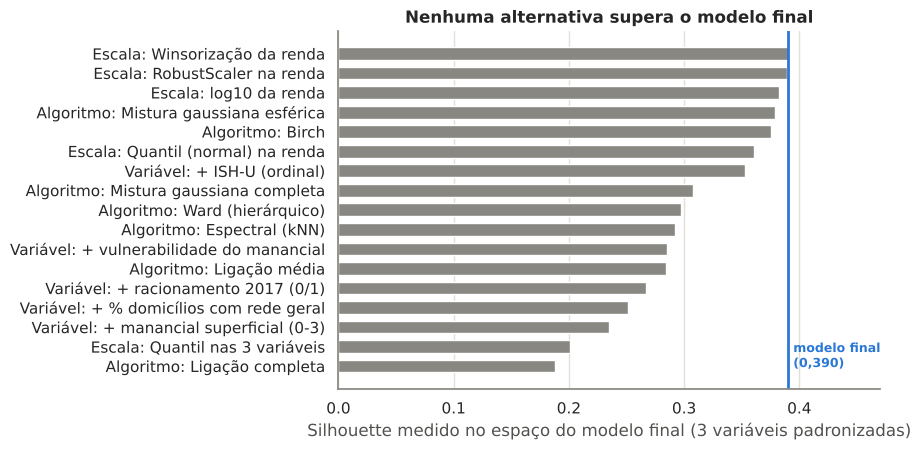

In [41]:
# ── 30.3 Robustez às variáveis: outras fontes como entrada do agrupamento (mesmos municípios e parâmetros) ──────
# Candidatas: ISH-U (ordinal), manancial superficial, vulnerabilidade do manancial, % de domicílios com rede geral (Censo 2022) e racionamento 2017.
rede = pd.read_csv('rede_geral_agua_censo2022_sp.csv', dtype={'codigo_ibge': str}); rede['chave6'] = rede['codigo_ibge'].str[:6]
cand_df = vi.merge(rede[['chave6', 'pct_rede_geral']], on='chave6', how='left')
cand_df['pct_rede_geral'] = cand_df['pct_rede_geral'].fillna(cand_df['pct_rede_geral'].median())
cand = {'Modelo final (3 variáveis)': base3, '+ ISH-U (ordinal)': base3 + ['ish_ord'], '+ manancial superficial (0-3)': base3 + ['superficial_ord'],
        '+ vulnerabilidade do manancial': base3 + ['vulnerab_manancial'], '+ % domicílios com rede geral': base3 + ['pct_rede_geral'],
        '+ racionamento 2017 (0/1)': base3 + ['racionamento_2017']}
linhas = []
for nome, cols in cand.items():
    Xv = StandardScaler().fit_transform(cand_df[cols].astype(float)); lab = KMeans(K_FINAL, init='k-means++', n_init=N_INIT, random_state=SEED, max_iter=500).fit_predict(Xv); tam = np.bincount(lab)
    linhas.append(dict(variaveis=nome, silhouette_proprio=silhouette_score(Xv, lab), silhouette_no_espaco_final=silhouette_score(X, lab),
                       ARI_vs_final=adjusted_rand_score(cand_df['cluster'], lab), menor_cluster=int(tam.min()),
                       alerta='cluster artificial (< 5% dos municípios)' if tam.min() < 0.05 * len(cand_df) else ''))
VARS = pd.DataFrame(linhas).set_index('variaveis'); display(VARS.round(3))
print('Nenhuma candidata eleva o Silhouette no espaço do modelo final; o racionamento (variável binária rara) só "melhora" o índice próprio '
      'ao isolar um grupo pequeno — um artefato. Por isso as fontes externas são usadas para VALIDAR (seção 29), não para agrupar.')

# Figura-síntese: Silhouette no espaço final por tipo de teste
fig, ax = plt.subplots(figsize=(9, 4.6))
resumo = pd.concat([ESCALAS['silhouette_no_espaco_final'].iloc[1:].rename(lambda s: 'Escala: ' + s), VARS['silhouette_no_espaco_final'].iloc[1:].rename(lambda s: 'Variável: ' + s),
                    ALGOS['silhouette'].iloc[1:].rename(lambda s: 'Algoritmo: ' + s)]).sort_values()
ax.barh(resumo.index, resumo.values, color='#898781', height=0.65)
ax.axvline(df_final['silhouette_i'].mean(), color='#2a78d6', lw=2); ax.set_xlim(0, 0.47)
ax.text(df_final['silhouette_i'].mean() + 0.005, 0.5, 'modelo final\n(0,390)', color='#2a78d6', fontsize=9, fontweight='bold', va='center')
ax.grid(axis='x', color=GRID); ax.set_axisbelow(True)
ax.set_xlabel('Silhouette medido no espaço do modelo final (3 variáveis padronizadas)'); ax.set_title('Nenhuma alternativa supera o modelo final')
plt.tight_layout(); plt.savefig('fig_robustez_resumo.png', dpi=200, bbox_inches='tight'); plt.show()


**Leitura.** Adicionar o ISH-U, o tipo e a vulnerabilidade do manancial, o acesso à rede geral de água (Censo 2022) ou o racionamento **reduz** o Silhouette no espaço do modelo final (de 0,390 para 0,235 a 0,353). O racionamento, por ser uma variável binária rara (4% dos municípios), mostra um índice próprio alto (0,388), mas isola um cluster de 24 municípios: é um artefato e não uma melhora, e por isso é usado só como variável de **validação** (seção 29). O resumo das três famílias de teste está na figura acima: **nenhuma alternativa supera o modelo final**.

**Conclusão da seção.** O teto de ~0,39 vem da própria estrutura dos dados, em que renda, perdas e CDD variam de forma contínua e com pouca separação natural em grupos, e não da escolha de escala, algoritmo ou variáveis. Melhorar o Silhouette de forma legítima exigiria dados menos ruidosos (próxima seção), e não mais variáveis.

---
## 31. Conclusões, limitações e próximos passos

**Solução final.** K-Means com k = 4 sobre renda per capita, índice de perdas e CDD padronizados, em 633 municípios paulistas, com Silhouette de 0,390. Os perfis, ordenados por índice de vulnerabilidade, são: **C1 Baixa** (117 municípios, renda alta), **C2 Moderada por baixa renda** (136, sul e litoral, CDD baixo), **C3 Moderada por exposição à seca** (278, interior norte e oeste, perdas baixas) e **C4 Alta, perdas elevadas** (102 municípios, perdas de ~46%).

**O que sustenta a solução.**
- A solução é estável (ARI de 0,98 entre sementes e 0,89 em bootstrap) e nenhuma escala, algoritmo ou variável adicional testada a supera.
- Os clusters têm validade externa: o racionamento da PNSB 2017 é mais frequente nos clusters de maior vulnerabilidade (9,8% no C4 e 4,3% no C3, contra 1,7% no C1 e 0% no C2; p = 0,0008), e o ISH-U difere entre os grupos (p = 10⁻⁸), com o C4 tendo a menor segurança hídrica.

**Correções aplicadas nesta versão.** (1) Perdas de 0,00% tratadas como dado ausente (10 municípios, a conferir no SNIS). (2) CDD dos 46 municípios sem pixel imputado por vizinhança geográfica (erro de 6,5 dias, contra 13,0 do método anterior). (3) Paleta única e rótulos estáveis nas figuras de cluster. (4) Textos das seções 5 a 27 reconferidos com as saídas.

**Limitações.**
- O Silhouette de 0,39 indica estrutura moderada: os clusters são uma partição de um contínuo e as fronteiras são graduais (30 municípios, 4,7%, têm Silhouette negativo, sobretudo no C1).
- O índice de vulnerabilidade pesa as três dimensões igualmente, uma escolha metodológica, e não inclui a dimensão de fonte hídrica (tipo de manancial), que o ISH-U sugere ser importante.
- As variáveis são de um único ano (2022); a PNSB usada na validação é de 2017.
- Os 46 CDD imputados são estimativas, e os 10 municípios sem perdas informadas estão fora do modelo.

**Próximos passos.**
1. **CDD multianual:** substituir o CDD de um único período pela mediana (ou p90) dos máximos anuais de vários anos, com o script `cdd_multianual.py`, aplicado à série diária do MERGE/INPE. É a melhoria mais provável de aumentar a separação dos grupos, por reduzir o ruído da variável climática.
2. **Perdas em vários anos (SNIS):** usar a mediana de 3 a 5 anos do IN049, em vez de um ano só, e conferir os 10 municípios com 0,00%.
3. **Dimensão de fonte hídrica:** avaliar o tipo de manancial (ISH-U) como uma segunda camada de análise (por exemplo, por cluster), já que como variável de entrada ele piora o agrupamento.